# Minería de datos aplicada a salarios

**Lama Jaber** · Máster en Data Science, Big Data & Business Analytics (UCM) · Minería de Datos

Este notebook recorre el ciclo completo de minería de datos sobre un conjunto de 6.684 empleados con su edad, género, nivel educativo, puesto, años de experiencia, salario, país y raza:

1. **Entendimiento y preparación de los datos**: exploración, relaciones entre variables, valores nulos, outliers y transformaciones.
2. **Regresión lineal** para predecir *Salary*, con comprobación de supuestos, validación cruzada, selección de variables (Forward) y regresión sobre componentes principales.
3. **Regresión logística** para predecir *Gender*, con análisis factorial previo y regularización LASSO.
4. **Clustering jerárquico aglomerativo** para identificar perfiles de empleados.

Las mismas variables se usan con objetivos distintos en cada bloque, por lo que algunas transformaciones son comunes y otras específicas de cada modelo.


In [1]:
#importar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.cluster.hierarchy as sch

from scipy import stats
from scipy.stats import chi2_contingency, shapiro
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist, squareform

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_squared_error, r2_score, make_scorer,
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve, accuracy_score
)
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer

import statsmodels.api as sm

from itertools import combinations

from factor_analyzer import FactorAnalyzer, calculate_kmo, calculate_bartlett_sphericity
from factor_analyzer.rotator import Rotator
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 60)

## 1. Carga de datos

Cada registro del fichero `Salary_MD.csv` es un empleado, con información laboral y de formación.

In [2]:
#Cargar el fichero de datos en un DataFrame
df = pd.read_csv('datos/Salary_MD.csv')

## 2. Exploración de los datos

In [3]:
#Mostrar los 10 primeros registros
df.head(10)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Country,Race,Senior
0,32,Male,1.0,Software Engineer,5.0,90000,UK,White,0
1,28,Female,2.0,Data Analyst,3.0,65000,USA,NaN,0
2,45,Male,3.0,Manager,15.0,150000,Canada,White,1
3,36,Female,1.0,Sales Associate,7.0,60000,USA,Hispanic,0
4,52,Male,2.0,Director,20.0,200000,USA,Asian,0
5,29,Male,1.0,Marketing Analyst,2.0,55000,USA,Hispanic,0
6,42,Female,2.0,Product Manager,12.0,120000,USA,Asian,0
7,31,Male,1.0,Sales Manager,4.0,80000,China,Korean,0
8,26,Female,1.0,Marketing Coordinator,1.0,45000,China,Chinese,0
9,38,Male,3.0,Scientist,10.0,110000,Australia,Australian,1


In [4]:
#Mostrar las columnas y tipos de datos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6684 entries, 0 to 6683
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6684 non-null   int64  
 1   Gender               6613 non-null   str    
 2   Education Level      6661 non-null   float64
 3   Job Title            6644 non-null   str    
 4   Years of Experience  6684 non-null   float64
 5   Salary               6684 non-null   int64  
 6   Country              6660 non-null   str    
 7   Race                 6521 non-null   str    
 8   Senior               6684 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 470.1 KB


Hay un total de 9 variables y un volumen de 6,684 registros. En cuanto a los tipos de datos, se observa que existen 5 variables numéricas: **Age**, **Education Level**, **Years of Experience** y **Senior**, y 4 variables categóricas: **Gender**, **Job Title**, **Country**, y **Race**.  

También podemos observar que las siguientes variables presentan valores nulos: **Gender**, **Education Level**, **Job Title**, **Country** y **Race**. Entre ellas, **Race** (con 163 valores faltantes) y **Gender** (con 71 valores faltantes) son las que tienen el volumen de nulos más alto y significativo, por lo que requerirán una estrategia de imputación o recategorización.

Será necesario tratar los valores faltantes y revisar la cardinalidad de las variables categóricas antes de la fase de modelado.
  

In [5]:
#Describir el DataFrame
df.describe()

,Age,Education Level,Years of Experience,Salary,Senior
count,6684.000000,6661.000000,6684.000000,6.684000e+03,6684.000000
mean,33.147816,1.623480,8.161655,1.164338e+05,0.143477
std,8.619754,0.880016,7.356860,6.738536e+04,0.350585
min,0.000000,0.000000,0.000000,0.000000e+00,0.000000
25%,28.000000,1.000000,3.000000,7.000000e+04,0.000000
50%,32.000000,1.000000,7.000000,1.150000e+05,0.000000
75%,38.000000,2.000000,12.000000,1.600000e+05,0.000000
max,110.000000,3.000000,200.000000,2.159320e+06,1.000000


El resumen estadístico muestra la distribución y el comportamiento de las cinco variables numéricas del dataset: **Age**, **Education Level**, **Years of Experience**, **Salary** y **Senior**.

**Age** presenta una media de aproximadamente 33 años, con un rango que va desde 0 hasta 110. La presencia de valores mínimos igual a 0 y máximos extremadamente altos sugiere posibles errores de registro o valores atípicos que deberán ser evaluados. La distribución parece concentrarse entre los 28 y 38 años (percentiles 25 y 75).

**Education Level** muestra una media de 1.62 y valores entre 0 y 3, lo que confirma que se trata de una variable ordinal con pocos niveles. La desviación estándar es baja, indicando poca variabilidad. También presenta algunos valores nulos, por lo que será necesario decidir una estrategia de imputación respetando su naturaleza ordinal.

**Years of Experience** tiene una media de 8.16 años y un rango muy amplio, desde 0 hasta 200. Este máximo tan elevado es claramente un valor atípico y deberá revisarse, ya que no es realista. La mayoría de los valores se concentran entre 3 y 12 años, según los percentiles.

**Salary** muestra una media de 116,433$ y una desviación estándar alta, lo que indica una distribución muy dispersa. El salario mínimo es 0 y el máximo supera los 2 millones, lo cual evidencia la presencia de valores extremos que pueden afectar correlaciones y modelos.

**Senior** es una variable binaria con una media de 0.14, lo que indica que solo alrededor del 14% de los registros corresponden a perfiles senior. La distribución está fuertemente concentrada en el valor 0, como muestran los percentiles.

Variables numéricas:  <StringArray>
['Age', 'Education Level', 'Years of Experience', 'Salary', 'Senior']
Length: 5, dtype: str


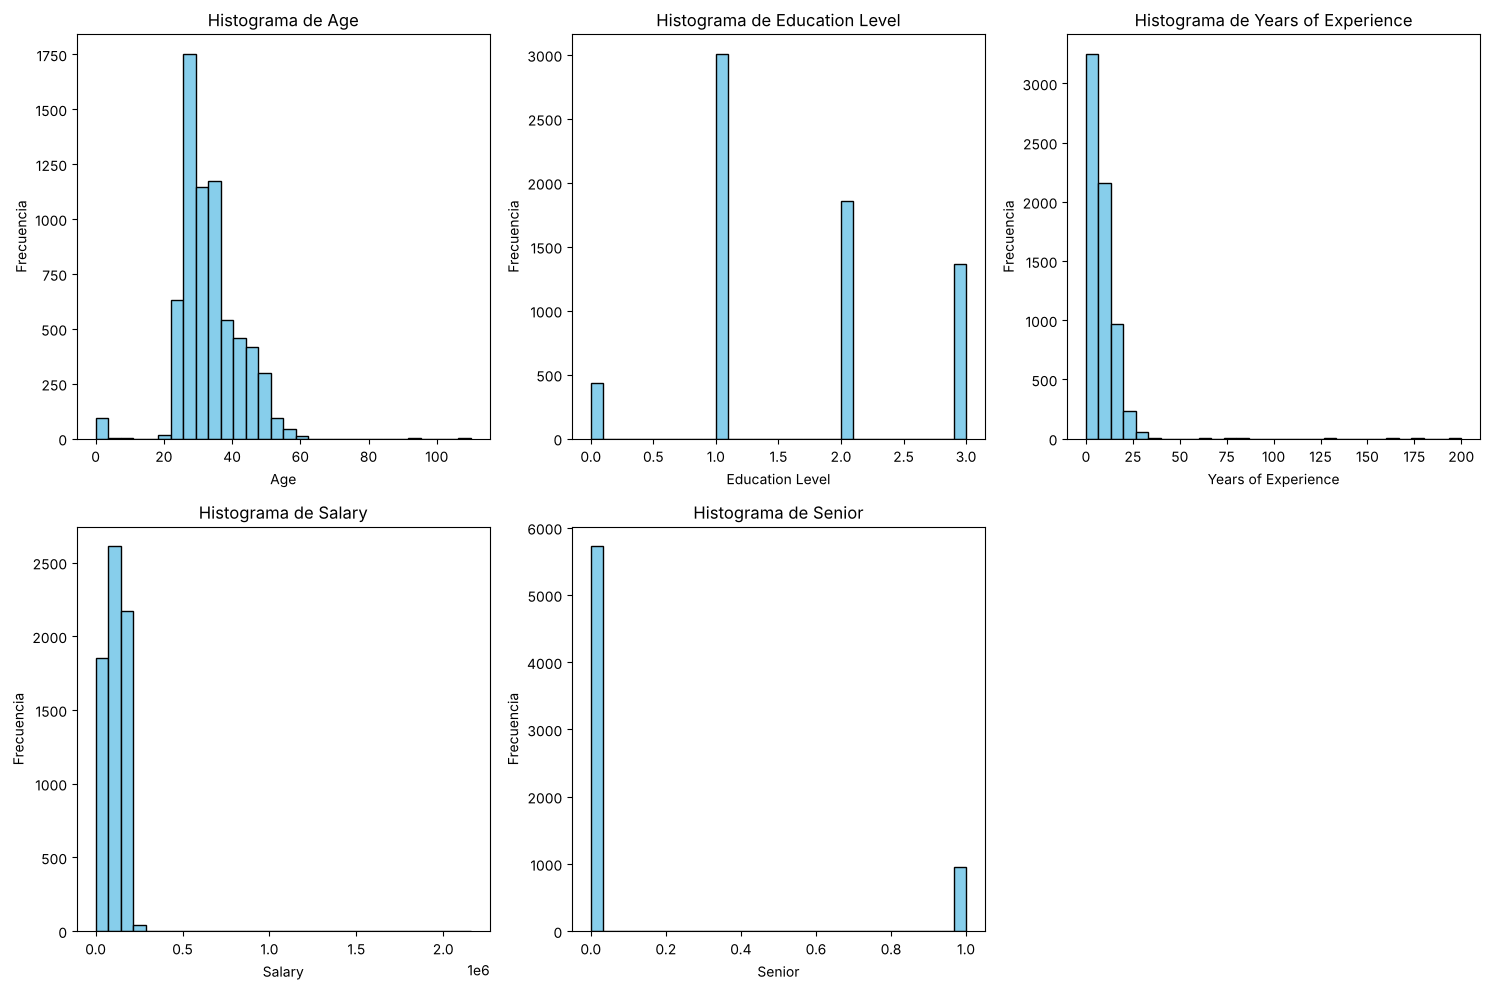

In [6]:
#Identificar las columnas numéricas
numeric_columns = df.select_dtypes(include=[np.number]).columns
print("Variables numéricas: ", numeric_columns.values)

#Crear una figura con subplots
num_vars = len(numeric_columns)
fig, axes = plt.subplots(nrows=(num_vars // 3) + 1, ncols=3, figsize=(15, 5 * ((num_vars // 3) + 1)))
axes = axes.flatten()

for i, col in enumerate(numeric_columns):
    #Graficar el histograma
    axes[i].hist(df[col].dropna(), bins=30, color='skyblue', edgecolor='black')
    axes[i].set_title(f'Histograma de {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frecuencia')

#Eliminar ejes sobrantes si hay menos de 3 variables
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

En el caso de **Age**, la distribución se concentra principalmente entre los 25 y ~37 años, lo que sugiere que la mayoría de los individuos se encuentran en etapas tempranos o medias de su vida laboral.

La variable **Education Level** muestra una distribución discreta y ordinal, donde el nivel 1 es el más frecuente, seguido por el nivel 2 y despues el 3. Esto refleja que la mayoría de los emploeados tienen un nivel educativo medio.

**Years of Experience** presenta una distribución sesgada hacia valores bajos. La mayoría de los registros se sitúan entre 0 y 5 años de experiencia, aunque existen valores extremos que son outliers.

En cuanto a **Salary**, la distribución es amplia y heterogénea, con concentraciones entre 50,000 y 200,000$ , pero también tiene valores extremos.

**Senior** muestra una distribución claramente binaria, donde la gran mayoría de los individuos no son senior.

Percentil 98 de Age: 52.0
Percentil 98 de Education Level: 3.0
Percentil 98 de Years of Experience: 23.0
Percentil 98 de Salary: 200000.0
Percentil 98 de Senior: 1.0


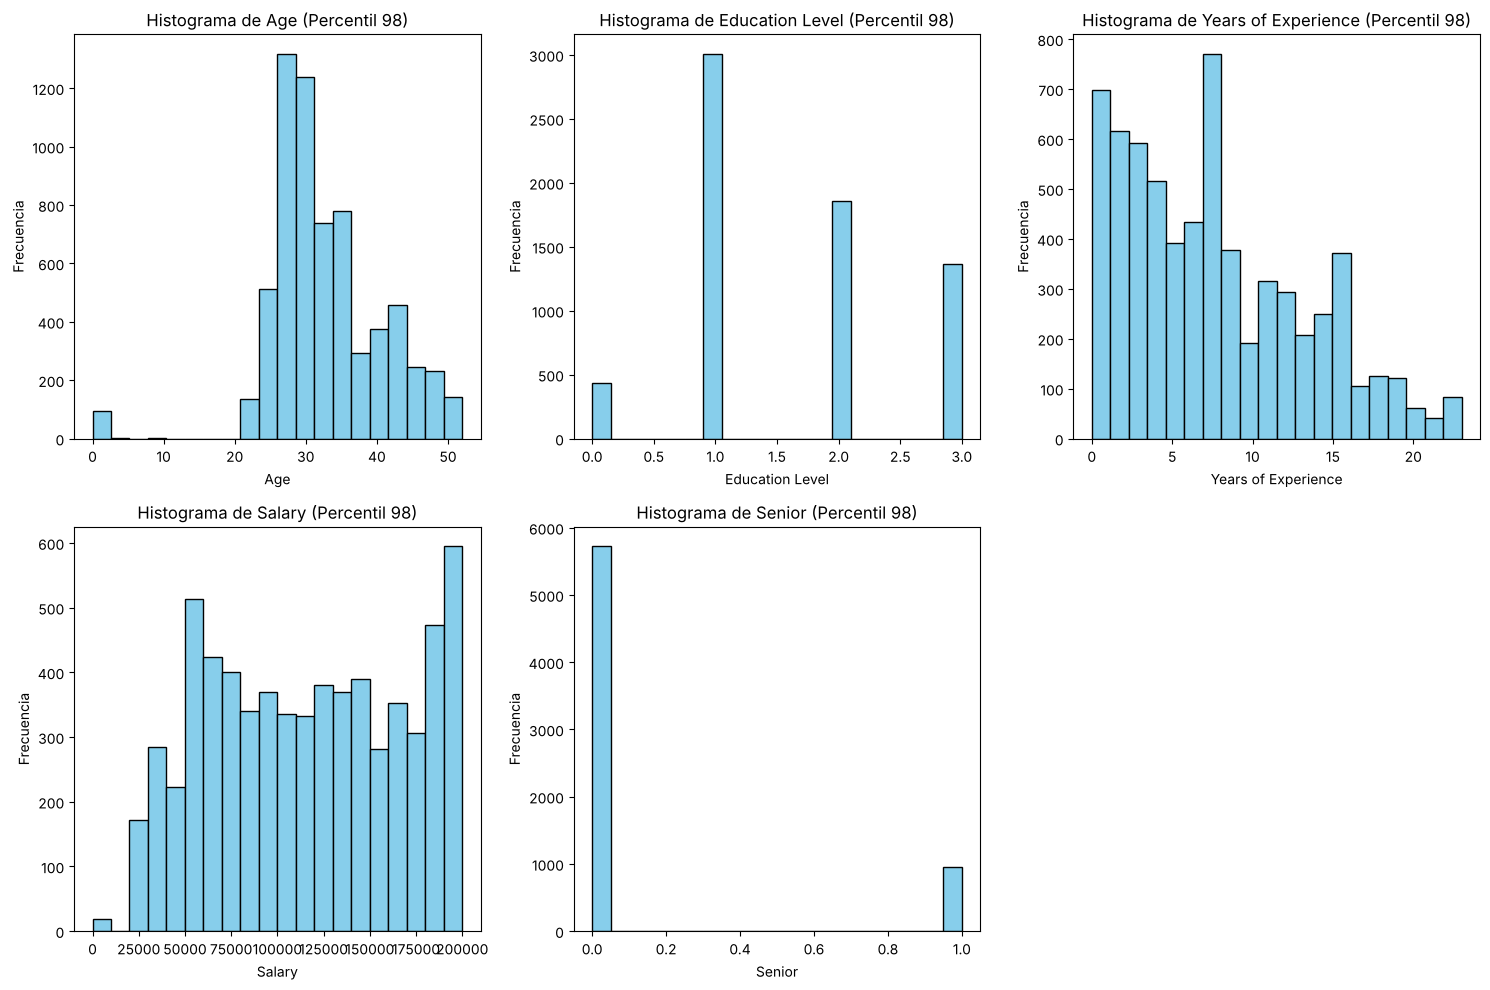

In [7]:
#Crear una función para graficar histogramas hasta el percentil X
def plot_histograms_percentile(df, x):

    #Crear una figura con subplots
    num_vars = len(numeric_columns)
    fig, axes = plt.subplots(nrows=(num_vars // 3) + 1, ncols=3, figsize=(15, 5 * ((num_vars // 3) + 1)))
    axes = axes.flatten()

    for i, col in enumerate(numeric_columns):
        #Calcular el percentil x de la variable
        if col == "year": perc = 100-x
        else: perc = x
        percent = np.percentile(df[col].dropna(), perc)
        print(f"Percentil {perc} de {col}: {percent}")

        #Filtrar los valores hasta el percentil x
        if col == "year":
            filtered_data = df[col][df[col] >= percent]
        else:
            filtered_data = df[col][df[col] <= percent]

        #Graficar el histograma
        axes[i].hist(filtered_data, bins=20, color='skyblue', edgecolor='black')
        axes[i].set_title(f'Histograma de {col} (Percentil {perc})')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Frecuencia')

    #Eliminar ejes sobrantes
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

#Llamar a la función para graficar
plot_histograms_percentile(df,98)

Se graficó con el percentil 98 para poder observar la distribución de las variables sin valores extremos/outliers.

In [8]:
#Cardinalidad de variables categoricas
cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    print(f"\n{col}  ({df[col].nunique()} categorías únicas):")
    print(df[col].value_counts().head(10))


Gender  (2 categorías únicas):
Gender
Male      3649
Female    2964
Name: count, dtype: int64

Job Title  (129 categorías únicas):
Job Title
Software Engineer            804
Data Scientist               511
Data Analyst                 387
Software Engineer Manager    376
Product Manager              320
Project Engineer             316
Marketing Manager            314
Full Stack Engineer          301
Back end Developer           239
Front end Developer          238
Name: count, dtype: int64

Country  (5 categorías únicas):
Country
USA          1350
China        1339
Australia    1329
UK           1328
Canada       1314
Name: count, dtype: int64

Race  (10 categorías únicas):
Race
White               1902
Asian               1560
Korean               445
Australian           439
Chinese              435
Black                430
African American     345
Welsh                326
Mixed                325
Hispanic             314
Name: count, dtype: int64


**Gender** presenta únicamente dos categorías: Male y Female, con una distribución relativamente equilibrada, aunque inclinada hacia el grupo masculino.
Esta baja cardinalidad facilita su codificación y análisis.

En contraste, **Job Title** es la variable con mayor complejidad ya que cuenta con 129 categorías únicas. Además, algunas categorías concentran un número elevado de registros, como Software Engineer o Data Scientist, mientras que muchas otras aparecen con frecuencias muy bajas. Esta alta cardinalidad puede generar problemas de dimensionalidad y sobreajuste si se codifica, por lo que será necesario agrupar/recategorizar los títulos profesionales en categorías más amplias.

Por otro lado, **Country** muestra una cardinalidad baja, con solo cinco países representados y una distribución muy homogénea entre ellos, lo que facilita tanto la imputación como la codificación.

Finalmente, **Race** presenta diez categorías distintas, con una distribución claramente desigual. Algunas categorías como White y Asian concentran la mayoría de los registros, mientras que otras como Welsh, Mixed o Hispanic tienen frecuencias mucho menores.

En conjunto, el análisis de cardinalidad revela que **Gender** y **Country** son variables sencillas de manejar, **Race** requiere cierta atención por su distribución desigual, y **Job Title** es la variable más problemática debido a su elevada cantidad de categorías.

### Primeras conclusiones sobre *Salary*, *Years of Experience* y *Job Title*

De este primer vistazo, vemos que **Salary** y **Years of Experience** presentan distribuciones sesgadas y con outliers. **Salary** presenta una dispersión muy grande y valores extremos, mientras que **Years of Experience** se concentra en valores bajos con una cola larga.

En cuanto a **Job Title**, se trata de una variable categorica de alta cardinalidad, con categorias muy frecuentes y otras muy raras, lo que la convierte en una varaible compleja de manejar en analisis y modelado.

### Relaciones entre variables

Analizo las correlaciones entre variables numéricas y la asociación entre variables categóricas (V de Cramér).

In [9]:
#Función para contar los ceros en cada columna numérica
def count_zeros(df):

    #Contar ceros en cada columna numérica
    zero_counts = df[numeric_columns].apply(lambda x: (x == 0).sum())

    return zero_counts

for i, col in enumerate(numeric_columns):
    zero_counts = count_zeros(df)
    print(f"Numero de 0s en {col}: {zero_counts[col]}")

Numero de 0s en Age: 94
Numero de 0s en Education Level: 432
Numero de 0s en Years of Experience: 162
Numero de 0s en Salary: 15
Numero de 0s en Senior: 5725


Percentil 100 de Age: 110.0
Percentil 100 de Education Level: 3.0
Percentil 100 de Years of Experience: 200.0
Percentil 100 de Salary: 2159320.0
Percentil 100 de Senior: 1.0


Percentil 98 de Age: 52.0
Percentil 98 de Education Level: 3.0
Percentil 98 de Years of Experience: 23.0
Percentil 98 de Salary: 200000.0
Percentil 98 de Senior: 1.0
Percentil 95 de Age: 49.0
Percentil 95 de Education Level: 3.0


Percentil 95 de Years of Experience: 19.0
Percentil 95 de Salary: 195000.0
Percentil 95 de Senior: 1.0


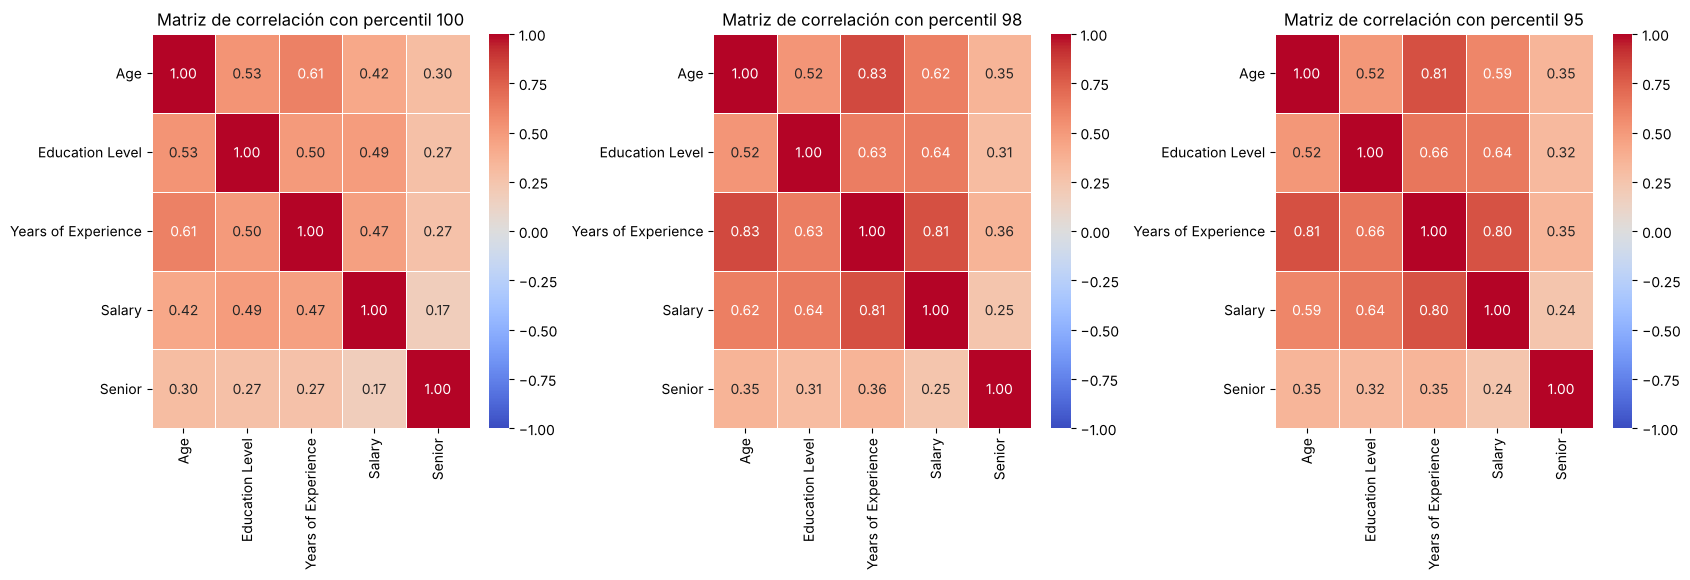

In [10]:
def corr_matrix_percent(df, x):
    filtered_df = df.copy()

    for col in numeric_columns:
        if df[col].isnull().all():
            continue

        #Calcular el percentil x de la variable (para eliminar outliers superiores)
        percent = np.percentile(df[col].dropna(), x)
        print(f"Percentil {x} de {col}: {percent}")

        #Filtrar el DataFrame, manteniendo valores hasta el percentil x
        filtered_df = filtered_df[filtered_df[col] <= percent]

    #Correlación entre variables numéricas
    correlation_matrix = filtered_df[numeric_columns].corr()
    return correlation_matrix

percentiles = [100,98,95]

fig, axes = plt.subplots(nrows=(len(percentiles) // 3) + 1, ncols=3, figsize=(17, 5 * ((len(percentiles) // 3) + 1)))
axes = axes.flatten()

for i, percentil in enumerate(percentiles):
    corr_matrix = corr_matrix_percent(df,percentil)

    #Graficar matriz
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=axes[i], vmin=-1, vmax=1)
    axes[i].set_title(f'Matriz de correlación con percentil {percentil}')

#Eliminar ejes sobrantes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

El análisis de los percentiles de las variables numéricas del dataset revela la presencia de valores extremos y potencialmente erróneos que afectan de manera significativa la interpretación estadística y la estructura de correlaciones.

En el percentil 100 se observan valores que no son realistas, como edades de hasta 110, 200 años de experiencia profesional y salarios superiores a dos millones. Estos valores constituyen outliers severos.

Al aplicar recortes en los percentiles 98 y 95, las variables adquieren rangos más coherentes. La edad se sitúa por debajo de 52, la experiencia profesional se reduce a un máximo de 23 años y los salarios se concentran en torno a 200.000$.

Con respecto a las matrices de correlación, en el percentil 100, las correlaciones entre las variables numéricas son moderadas, debido a la influencia de los outliers que introducen ruido y reducen la linealidad de las relaciones.

Sin embargo, al recortar los valores extremos (percentil 98), las correlaciones aumentan de manera notable. Destacan especialmente las relaciones entre Years of Experience y Salary, así como entre Age y Years of Experience, que alcanzan valores superiores a 0.80.

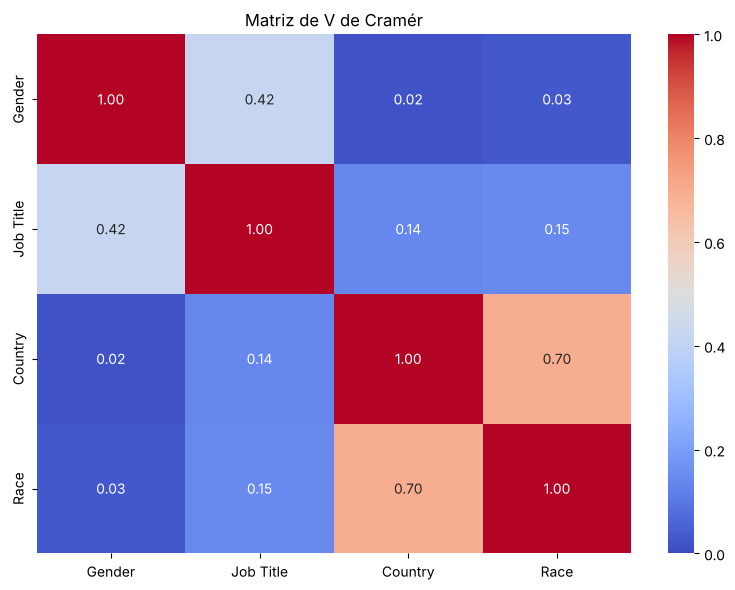

In [11]:
#Función para calcular el coeficiente V de Cramér entre variables categóricas
def cramers_v(x, y):
    confusion_matrix_cv = pd.crosstab(x, y)
    chi2, _, _, _ = chi2_contingency(confusion_matrix_cv)
    n = confusion_matrix_cv.sum().sum()
    k = min(confusion_matrix_cv.shape)
    return np.sqrt(chi2 / (n * (k - 1)))

all_cat = [c for c in cat_cols]
v_matrix = pd.DataFrame(np.zeros((len(all_cat), len(all_cat))),
                        index=all_cat, columns=all_cat)

for v1, v2 in combinations(all_cat, 2):
    # Eliminar filas con nulos en ambas variables para el cálculo
    sub = df[[v1, v2]].dropna()
    val = cramers_v(sub[v1], sub[v2])
    v_matrix.loc[v1, v2] = val
    v_matrix.loc[v2, v1] = val

for v in all_cat:
    v_matrix.loc[v, v] = 1

plt.figure(figsize=(8, 6))
sns.heatmap(v_matrix.astype(float), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=0, vmax=1)
plt.title('Matriz de V de Cramér')
plt.tight_layout()
plt.show()

La matriz de V de Cramér revela diferencias claras en el nivel de asociación entre las variables categóricas del dataset.

La relación más fuerte se observa entre **Country** y **Race**, con un valor de 0.70, lo que indica una asociación alta. Este resultado es coherente ya que la composición racial está vinculada al país de origen, por lo que esta dependecia es esperable y aporta información relevante sobre la estructura demoráfica del dataset.

Por otro lado, la asociación entre **Gender** y **Job Title**, presenta un valor moderado de 0.42. Esto sugiere que ciertos roles laborales están distribuidos de manera diferente entre hombres y mujeres, lo cual puede reflejar tendencias reales del mercado laboral. Aunque no es una asociación extremadamente fuerte, sí es lo suficientemente relevante como para considerarla en análisis posteriores.

Las demás asociaciones entre variables muestran valores bajos, entre 0.02 y 0.15, lo que indica que no existe una relación significativa entre ellas.

### Relaciones más destacadas entre variables

Las matrices muestran varias relaciones claras entre variables numéricas y categóricas.

En el caso de las variables numéricas, si nos fijamos en el percentil 98, las asociaciones más fuertes aparecen entre **Age**, **Salary** y **Years of Experience**, que presentan correlaciones altas y positivas entre si. Esto sugiere que, en general, a mayor edad también se observan un salario mas alto y más años de experiencia, lo cual es coherente con trayectorias laborales típicas.

Asimismo, **Education Level** muestra correlaciones positivas con estas tres variables indicando que con un nivel educativo mas alto, la edad, los años de experiencia y los salarios aumentan.

La variable **Senior** presenta correlaciones más bajas con el resto, lo que sugiere que ser "senior" no depende únicamente de edad, educación o experiencia, sino probablemente de criterios internos de cada empresa.

En cuanto a las variables categóricas, la relación más destacada es la asociación muy alta entre **Country** y **Race**, lo cual indica que la distribución racial está fuertemente vinculada al pais de origen. También se observa una relación moderada entre **Gender** y **Job Title**, lo que sugiere cierta segregación ocupacional por género. Las demás asociaciones entre variables categóricas son bajas, indicando que no existe una dependencia fuerte entre ellas.


## 3. Calidad del dato: valores nulos

In [12]:
#Tabla de porcentaje de registros con Missing Values por cada variable
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_summary = pd.DataFrame({'Nulos': missing, 'Porcentaje (%)': missing_pct})
print(missing_summary.sort_values('Porcentaje (%)', ascending=False))

                     Nulos  Porcentaje (%)
Race                   163        2.438659
Gender                  71        1.062238
Job Title               40        0.598444
Country                 24        0.359066
Education Level         23        0.344105
Age                      0        0.000000
Years of Experience      0        0.000000
Salary                   0        0.000000
Senior                   0        0.000000


El resumen muestra que las variables categóricas presentan valores nulos, mienstras que todas las variables numéricas, excepto **Education Level**, están completas.

**Race** es la variable con mayor cantidad de valores faltantes, con 163 nulos. Además, Race ya tenía categorías poco frecuentes, por lo que imputar o agrupar es coherente.

**Gender** tiene 71 nulos (1.06%), un porcentaje bajo, pero es una variable clave en el análisis. Los registros con **Gender** nulo tienen diferencias salariales significativas, por lo que imputar es necesario para no perder información.

**Job Title** tiene pocos nulos (40) pero como tiene alta cardinalidad es necesario recodificar.

**Country** tiene muy pocos nulos (24) y una distribución muy homogénea. Se puede imputar usando la moda.

**Education Level** también tiene muy pocos nulos (23) y se puede imputar con la moda.

In [13]:
#Cuenta de valores nulos por registro
null_per_row = df.isnull().sum(axis=1)
summary_rows = null_per_row.value_counts().reset_index()
summary_rows.columns = ['num_nulos', 'registros']
summary_rows = summary_rows.sort_values('num_nulos')
print("Distribución de nulos por fila:")
print(summary_rows)

Distribución de nulos por fila:
   num_nulos  registros
0          0       6461
1          1        161
2          2         32
3          3         24
4          4          6


La gran mayoría de los registros (6461) no tienen ningún valor nulo. Esto signfica que 96.6% del dataset está completamente limpio. No tendremos que eliminar muchas filas ni preocuparnos por pérdida de información.


161 registros tienen execatamente 1 valor nulo. Son fáciles de imputar y no afectan la estructura general.

In [14]:
#¿Existe relación entre Gender nulo y Salary?
salary_gender_null = df[df['Gender'].isna()]['Salary']
salary_gender_no_null = df[df['Gender'].notna()]['Salary']

print("Salario MEDIO cuando Gender es nulo:", round(salary_gender_null.mean(), 2))
print("Salario MEDIO cuando Gender NO es nulo:", round(salary_gender_no_null.mean(), 2))
print()
print("Salario MEDIANO cuando Gender es nulo:", salary_gender_null.median())
print("Salario MEDIANO cuando Gender NO es nulo:", salary_gender_no_null.median())

Salario MEDIO cuando Gender es nulo: 145387.79
Salario MEDIO cuando Gender NO es nulo: 116122.97

Salario MEDIANO cuando Gender es nulo: 180000.0
Salario MEDIANO cuando Gender NO es nulo: 115000.0


In [15]:
#Test estadístico
g_null = salary_gender_null.dropna()
g_notnull = salary_gender_no_null.dropna()
if len(g_null)>0 and len(g_notnull)>0:
    stat, p = stats.mannwhitneyu(g_null, g_notnull, alternative='two-sided')
    print("Mann-Whitney U p-value:", p)

Mann-Whitney U p-value: 1.5957786208976404e-06


### Nulos de *Gender* e imputación

El valor p obtenido en la prueba Mann-Whitney U indica que existe una diferencia estadísticamente signficativa entre las distribuciones salariales de los registros donde **Gender** está nulo y aquellos donde **Gender** está presente.

Esto confirma que los salarios de los registros con **Gender** nulo son consistentemente más altos que los del resto del dataset. Esto se refleja en las medias y medianas calculadas.

Esto indica que los registros sin información de género no son aleatorios ya que parecen corresponder a personas con salarios. Quizá ciertos perfiles profesionales o países no reportan género, o ciertos cargos altons tienen más omisiones.

Dado que eliminar estos 71 registros implicaría perder información valiosa y sesgar el análisis hacia salarios más bajos, se imputará el valor faltante utilizando la moda de la variable, que en este caso corresponde a "Male".

Esta estrategia es adecuada porque **Gender** es una variable binaria con una distribución relativamente equilibrada (aproximadamente 55% Male y 45% Female), y los valores nulos representan apenas un 1% del total.

## 4. Valores atípicos

Antes de tratar los nulos, identifico los valores atípicos con dos métodos: Z-score y rango intercuartílico (IQR).

In [16]:
#Identificación de outliers (Z-score)
print("Outliers por Z-score")
for col in numeric_columns:
    series = df[col].dropna()
    z = np.abs(stats.zscore(series))
    n_out = (z > 3).sum()
    print(f"  {col}: {n_out} outliers ({100*n_out/len(series):.2f}%)")

Outliers por Z-score
  Age: 110 outliers (1.65%)
  Education Level: 0 outliers (0.00%)
  Years of Experience: 28 outliers (0.42%)
  Salary: 8 outliers (0.12%)
  Senior: 0 outliers (0.00%)


In [17]:
#Identificación de outliers (IQR)
print("Outliers por IQR")
for col in numeric_columns:
    series = df[col].dropna()
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n_out = ((series < lower) | (series > upper)).sum()
    print(f"  {col}: {n_out} outliers ({100*n_out/len(series):.2f}%)")
    print(f"         Rango normal: [{lower:.1f}, {upper:.1f}]")

Outliers por IQR
  Age: 217 outliers (3.25%)
         Rango normal: [13.0, 53.0]
  Education Level: 0 outliers (0.00%)
         Rango normal: [-0.5, 3.5]
  Years of Experience: 76 outliers (1.14%)
         Rango normal: [-10.5, 25.5]
  Salary: 8 outliers (0.12%)
         Rango normal: [-65000.0, 295000.0]
  Senior: 959 outliers (14.35%)
         Rango normal: [0.0, 0.0]


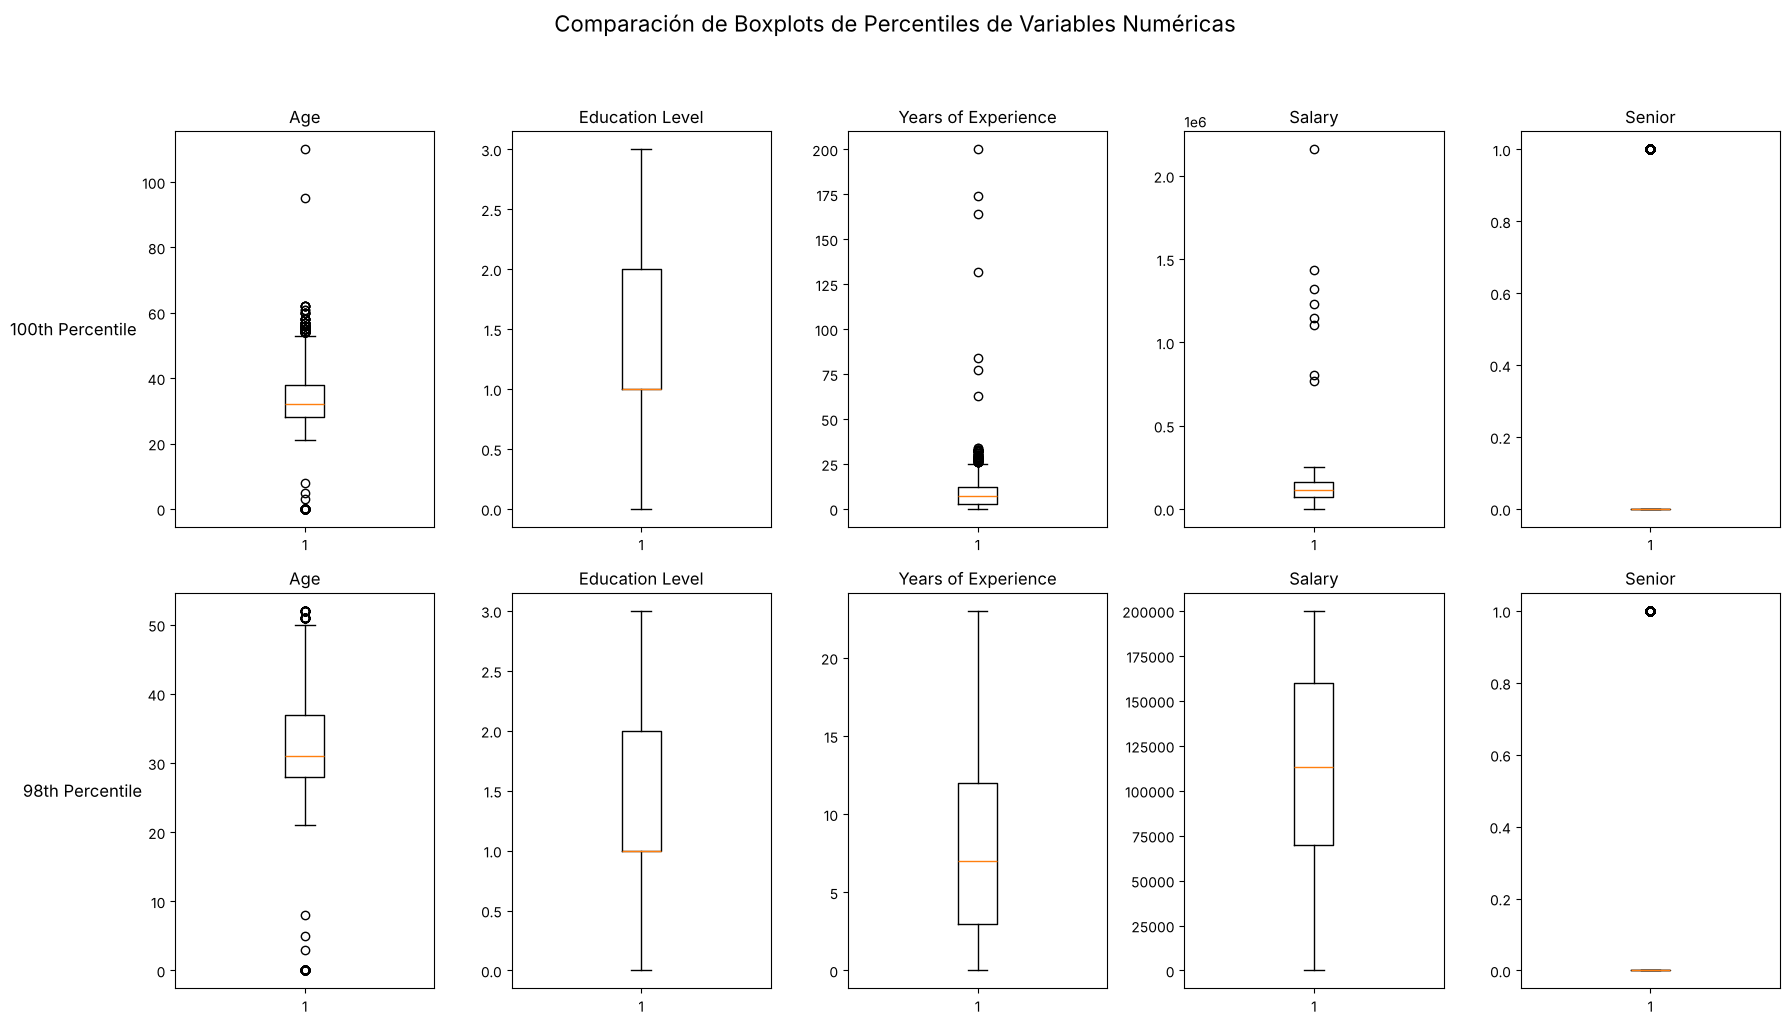

In [18]:
if 'numeric_columns' not in globals():
    numeric_columns = df.select_dtypes(include=[np.number]).columns

#Dos filas de boxplots
fig, axes = plt.subplots(2, len(numeric_columns), figsize=(18, 10))

fig.suptitle('Comparación de Boxplots de Percentiles de Variables Numéricas', fontsize=16, y=1.02)

#Boxplots para el 100 percentil
for i, col in enumerate(numeric_columns):
    ax = axes[0, i]
    ax.boxplot(df[col].dropna())
    ax.set_title(col)
    if i == 0:
        ax.set_ylabel('100th Percentile', rotation=0, ha='right', va='center', fontsize=12)

# Boxplots para el 98 percentil (fila inferior)
for i, col in enumerate(numeric_columns):
    ax = axes[1, i]
    percentile_98 = np.percentile(df[col].dropna(), 98)
    filtered_data = df[col][df[col] <= percentile_98].dropna()
    ax.boxplot(filtered_data)
    ax.set_title(col)
    if i == 0:
        ax.set_ylabel('98th Percentile', rotation=0, ha='right', va='center', fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

### Outliers: Z-score frente a IQR

Las variables numéricas continuas que presentan outliers son **Age**, **Salary** y **Years of Experience**, aunque cada una require un método distinto para identificarlos adecuadamente.

En **Age**, tanto le IQR como el Z-score detectan valores atípicos, pero el IQR identifica más casos (217 vs 110), incluyendo edades claramente erróneas como 0 o extramadamente altas como 110. Dado que la distribución no es perfectamente normal y existen valores imposibles en un contexto laboral, el IQR es el método más apropiado para esta variable.

En **Years of Experience**, ocurre algo similar. El IQR detecta 76 outliers y el Z-score solo 28, pero la presencia de valores imposibles como 200 años de experiencia y la fuerte asimetría hacia la derecha hacen que el IQR sea la mejor opción.


Para **Salary** ambos métodos detectan únicamente 8 outliers (0.12%), lo que indica que los salarios excepcionalmente altos son muy pocos y que la distribución salarial es relativamente estable dentro del rango normal de 65 000 a 295 000$.

Finalmente, el IQR marca 959 "outliers" en **Senior**, pero este resultado se puede ignorar. Al ser una variable binaria, el rango normal queda fijado en [0, 0], lo que hace que todos los valores “1” sean clasificados erróneamente como outliers.

En resumen, estos resultados indican que IQR funciona bien para variables continuas como edad, experiencia y salario, pero no es adecuado para variables discretas o binarias, donde puede generar falsos positivos.

## 5. Limpieza de nulos y outliers

In [19]:
data = df.copy()

In [20]:
#Seleccion/Eliminación de registros y variables

#Age: entre 18 y 65 años (rango laboral razonable)
data = data[(data['Age'] >= 18) & (data['Age'] <= 65)]

#Years of Experience: máximo razonable 45 años
data = data[data['Years of Experience'] <= 45]

#Salary: eliminar registros con Salary = 0
data = data[data['Salary'] > 0]

print("Registros tras eliminar valores imposibles:", data.shape[0])

Registros tras eliminar valores imposibles: 6582


In [21]:
#Imputación de valores
mode_gender = data["Gender"].mode()[0]
data["Gender"] = data["Gender"].fillna(mode_gender)

for col in ["Country", "Education Level", "Race", "Job Title"]:
    data[col] = data[col].fillna(data[col].mode()[0])

print("Nulos restantes:")
print(data.isnull().sum())

Nulos restantes:
Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
Country                0
Race                   0
Senior                 0
dtype: int64


In [22]:
def iqr_cap(df, variable):
    Q1 = df[variable].quantile(0.25)
    Q3 = df[variable].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[variable] = np.where(df[variable] < lower, lower,
                            np.where(df[variable] > upper, upper, df[variable]))

    print(f"\nLímite superior {variable} (winsorizacion): {upper:.0f}")
    print(f"Nuevo máximo de {variable}:", df[variable].max())
    print(f"Estadísticos {variable} tras winsorización:")
    print(df[variable].describe())
    return df

numeric_vars = ["Age", "Years of Experience", "Salary"]

for var in numeric_vars:
    data = iqr_cap(data, var)


Límite superior Age (winsorizacion): 53
Nuevo máximo de Age: 53.0
Estadísticos Age tras winsorización:
count    6582.000000
mean       33.565330
std         7.466253
min        21.000000
25%        28.000000
50%        32.000000
75%        38.000000
max        53.000000
Name: Age, dtype: float64

Límite superior Years of Experience (winsorizacion): 26
Nuevo máximo de Years of Experience: 25.5
Estadísticos Years of Experience tras winsorización:
count    6582.000000
mean        8.012458
std         5.915290
min         0.000000
25%         3.000000
50%         7.000000
75%        12.000000
max        25.500000
Name: Years of Experience, dtype: float64

Límite superior Salary (winsorizacion): 295000
Nuevo máximo de Salary: 250000.0
Estadísticos Salary tras winsorización:
count      6582.000000
mean     115339.465512
std       52833.290898
min         350.000000
25%       70000.000000
50%      115000.000000
75%      160000.000000
max      250000.000000
Name: Salary, dtype: float64


### Tratamiento de los outliers de *Salary*

Los outliers de **Salary** han sido tratados con una combinación de limpieza previa y winsorización para conservar registros y reducir el efecto de valores extremos. Primero, se eliminaron registros imposibles o erróneos, dejando 6,582 observaciones.

El resultado que se obtuvo tras aplicar la winsorización mediante IQR muestra que el procedimiento funcionó correctamente y que la distribución salarial quedó suavizada sin perder su estructura original.

El nuevo límite superior del salario se fijó en 250,000, que corresponde al valor máximo dentro del rango permitido. Todos los salarios que excedían ese umbral fueron recortados a ese valor. Esto se refleja en que el nuevo máximo del salario es exactamente 250,000, confirmando que los outliers extremos fueron controlados.

Tras la winsorización, los estadísticos relevantes son: media = 115,339.47, desviación estándar = 52,833.29, mediana = 115,000, Q1 = 70,000, Q3 = 160,000.

Se seleccionó la winsorización porque los outliers eran pocos y muy extremos. Al recortarlos se preserva la mayoría de la información y reduce la influencia desproporcionada de unos pocos salarios muy altos sobre la media. Además, el uso del IQR para definir el umbral es robusto frente a la asimetría de la distribución salarial y evita que la desviación estándar inflada por los extremos falsee la detección de atípicos.

## 6. Transformaciones de variables

In [23]:
print("Correlación YoE con Salary:", round(data['Years of Experience'].corr(data['Salary']), 4))
data = data.drop(columns=['log_YoE'], errors='ignore')

Correlación YoE con Salary: 0.8176


In [24]:
def categorize_job(title):
    title_lower = str(title).lower()

    #Categorías técnicas
    tech_keywords = ['software', 'developer', 'engineer', 'full stack', 'backend', 'front end',
                     'devops', 'web', 'qa', 'tester', 'architect', 'cloud']

    data_keywords = ['data', 'analyst', 'scientist', 'machine learning', 'ml', 'ai',
                     'business intelligence', 'bi', 'analytics']

    #Categorías de negocio
    management_keywords = ['manager', 'director', 'vp', 'chief', 'ceo', 'cto', 'president',
                           'head', 'lead', 'supervisor']

    marketing_keywords = ['marketing', 'sales', 'account', 'coordinator', 'brand',
                          'content', 'seo', 'sem']

    hr_keywords = ['hr', 'human resources', 'recruiter', 'talent', 'people']

    finance_keywords = ['finance', 'financial', 'accountant', 'controller', 'supply chain',
                        'operations analyst', 'procurement']

    admin_keywords = ['receptionist', 'office', 'administrative', 'assistant', 'support',
                      'secretary', 'clerk']

    product_keywords = ['product', 'project', 'scrum', 'agile', 'program manager']

    #Clasificación
    if any(k in title_lower for k in tech_keywords):
        return 'Tech Engineering'
    elif any(k in title_lower for k in data_keywords):
        return 'Data & Analytics'
    elif any(k in title_lower for k in management_keywords):
        return 'Management'
    elif any(k in title_lower for k in marketing_keywords):
        return 'Marketing & Sales'
    elif any(k in title_lower for k in hr_keywords):
        return 'HR'
    elif any(k in title_lower for k in finance_keywords):
        return 'Finance & Operations'
    elif any(k in title_lower for k in admin_keywords):
        return 'Administrative'
    elif any(k in title_lower for k in product_keywords):
        return 'Product & Project'
    elif title_lower in ['nan', '', 'none']:
        return 'Unknown'
    else:
        return 'Other'

data['Job_Category'] = data['Job Title'].apply(categorize_job)
print("Distribución de Job_Category:")
print(data['Job_Category'].value_counts())

Distribución de Job_Category:
Job_Category
Tech Engineering        2621
Management              1740
Data & Analytics        1297
Marketing & Sales        611
HR                       106
Product & Project         78
Administrative            63
Other                     61
Finance & Operations       5
Name: count, dtype: int64


In [25]:
#Revisión de Education Level & Race
print("Distribución de Education Level")
print(data['Education Level'].value_counts().sort_index())
print("Distribución de Race")
print(data['Race'].value_counts())

Distribución de Education Level
Education Level
0.0     426
1.0    2979
2.0    1830
3.0    1347
Name: count, dtype: int64
Distribución de Race
Race
White               2019
Asian               1544
Korean               441
Australian           433
Chinese              432
Black                422
African American     338
Welsh                323
Mixed                322
Hispanic             308
Name: count, dtype: int64


La nueva distribución de la variable **Race** muestra valores ligeramente diferentes a los obtenidos en la exploración inicial, lo cual indica que el dataset ha sido transformado.

Los siguientes cambios fueron observados:
- White pasa de 1902 a 2019 registros
- Asian: 1560 a 1544
- Koren: 445 a 441
- Australian: 439 a 433
- Chinese: 435 a 432
- Black: 430 a 422
- African American: 345 a 338
- Welsh: 326 a 323
- Mixed: 325 a 322
- Hispanic: 314 a 308

In [26]:
#Preparación para regresión lineal
data_reglin = data.copy()

#Codificación One-Hot de variables categóricas (excepto Education Level)
data_reglin = pd.get_dummies(data_reglin,
                         columns=['Gender', 'Country', 'Race', 'Job_Category'],
                         drop_first=True)

#Eliminar columna original de Job Title (sustituida por Job_Category)
data_reglin = data_reglin.drop(columns=['Job Title'])

#Convertir booleanos a enteros
bool_cols = data_reglin.select_dtypes(include='bool').columns
data_reglin[bool_cols] = data_reglin[bool_cols].astype(int)

#Asegurar que todo es numérico
data_reglin = data_reglin.apply(pd.to_numeric, errors='coerce').dropna()

print("Shape del dataset para regresión lineal:", data_reglin.shape)
print("Variables del dataset:")
print(list(data_reglin.columns))


Shape del dataset para regresión lineal: (6582, 27)
Variables del dataset:
['Age', 'Education Level', 'Years of Experience', 'Salary', 'Senior', 'Gender_Male', 'Country_Canada', 'Country_China', 'Country_UK', 'Country_USA', 'Race_Asian', 'Race_Australian', 'Race_Black', 'Race_Chinese', 'Race_Hispanic', 'Race_Korean', 'Race_Mixed', 'Race_Welsh', 'Race_White', 'Job_Category_Data & Analytics', 'Job_Category_Finance & Operations', 'Job_Category_HR', 'Job_Category_Management', 'Job_Category_Marketing & Sales', 'Job_Category_Other', 'Job_Category_Product & Project', 'Job_Category_Tech Engineering']


El dataset final tiene 6,582 filas y 27 columnas, lo que confirma que la codificación añadió únicamente las columnas necesarias sin alterar el número de registros.

Las variables nominales **Gender**, **Country**, **Race** y **Job_Category** fueron transformadas en dummies con drop_first=True, lo que elimina la primera categoría de cada variable para evitar multicolinealidad en modelos lineales. Las columnas generadas muestran que todas las categorías relevantes fueron correctamente convertidas en variables binarias. Por ejemplo, Gender_Male representa la categoría distante de la base Female, Country_Canada, Country_China, Country_UK y Country_USA representan los países distintos del país base, y las categorías de **Race** y **Job_Category** aparecen completas y sin pérdidas.

### Variables categóricas y *Education Level*

Se han llevado a cabo las siguientes transformacioes sobre las variables categóricas:

**Job Title** fue recategorizada en 9 grupos funcionales. Esta variable contaba con 129 categorías distintas, muchas de ellas con muy pocos registros. Tener tantas categorías en un modelo genera problemas de representatividad estadística. Por ello las agrupé en 10 categorías funcionales con sentido semántico: Tech Engineering (2,621 registros), Management (1,740), Data & Analytics (1,297), Marketing & Sales (611), HR (106), Product & Project (78),Administrative (63), y Other (61). La categoría Finance & Operations quedó con solo 5 registros, entonces podría fusionarla con Other antes del modelado.

A **Gender**, **Country**, **Race** y **Job_Category** fueron codificadas ya que son variables nominales y no tienen un orden natural entre sus categorías. Una columna binaria fue generada por cada categoría excepto la de referencia. Tras esta codificación el dataset pasa de 11 a 29 columnas, con 22 variables dummy generadas.

**Race** se ha dejado con sus 10 categorías originales sin agrupar, ya que todas tienen más de 300 registros, lo que garantiza representatividad estadística suficiente para el modelado.

Respecto a **Education Level**, se ha mantenido como variable numérica oridinal y no se ha codificado. La razón es que esta variable refleja un orden real y creciente: 0 = Sin estudios, 1 = Bachelor, 2 = Master, 3 = PhD. Convertirla en dummies rompería esa estructura ordinal. Al mantenerla como numérica, el modelo puede capturar directamente que a mayor nivel educativo, mayor salario.

## 7. Regresión lineal: predicción de *Salary*

El primer modelo trata de predecir el salario a partir del resto de variables.

### Preparación específica para la regresión lineal

In [27]:
#Estandarización de variables numéricas
data_final = data_reglin.copy()

cols_to_scale = ['Age', 'Years of Experience', 'Salary', 'Education Level']
scaler = StandardScaler()

data_scaled = data_final.copy()
data_scaled[cols_to_scale] = scaler.fit_transform(data_final[cols_to_scale])

print("Estadísticos tras estandarizar (media ≈ 0, std ≈ 1):")
print(data_scaled[cols_to_scale].describe().round(3))

Estadísticos tras estandarizar (media ≈ 0, std ≈ 1):
            Age  Years of Experience    Salary  Education Level
count  6582.000             6582.000  6582.000         6582.000
mean      0.000                0.000     0.000            0.000
std       1.000                1.000     1.000            1.000
min      -1.683               -1.355    -2.177           -1.845
25%      -0.745               -0.847    -0.858           -0.708
50%      -0.210               -0.171    -0.006           -0.708
75%       0.594                0.674     0.845            0.429
max       2.603                2.957     2.549            1.566


Los estadísticos confirman que la estandarización mediante StandardScaler se aplicó correctamente a todas las variables numéricas. Cada una de ellas **Age**, **Years of Experience**, **Salary** y **Education Level** presenta una media igual a 0 y una desviación estándar igual a 1, lo cual es exactamente el comportamiento esperado.

In [28]:
#Verificación final del dataset preparado
print(f"Registros: {data_scaled.shape[0]}")
print(f"Variables: {data_scaled.shape[1]}")
print()
print("Variables numéricas originales:",
      [c for c in data_scaled.select_dtypes(include='number').columns
       if c not in [col for col in data_scaled.columns if '_' in col]])
print()
print("Variables dummy generadas:",
      [c for c in data_scaled.columns if any(
          c.startswith(p) for p in ['Gender','Country','Race','Job_'])])
print()
print("Vista general:")
data_scaled.head(5)

Registros: 6582
Variables: 27

Variables numéricas originales: ['Age', 'Education Level', 'Years of Experience', 'Salary', 'Senior']

Variables dummy generadas: ['Gender_Male', 'Country_Canada', 'Country_China', 'Country_UK', 'Country_USA', 'Race_Asian', 'Race_Australian', 'Race_Black', 'Race_Chinese', 'Race_Hispanic', 'Race_Korean', 'Race_Mixed', 'Race_Welsh', 'Race_White', 'Job_Category_Data & Analytics', 'Job_Category_Finance & Operations', 'Job_Category_HR', 'Job_Category_Management', 'Job_Category_Marketing & Sales', 'Job_Category_Other', 'Job_Category_Product & Project', 'Job_Category_Tech Engineering']

Vista general:


,Age,Education Level,Years of Experience,Salary,Senior,Gender_Male,Country_Canada,Country_China,Country_UK,Country_USA,Race_Asian,Race_Australian,Race_Black,Race_Chinese,Race_Hispanic,Race_Korean,Race_Mixed,Race_Welsh,Race_White,Job_Category_Data & Analytics,Job_Category_Finance & Operations,Job_Category_HR,Job_Category_Management,Job_Category_Marketing & Sales,Job_Category_Other,Job_Category_Product & Project,Job_Category_Tech Engineering
0,-0.209670,-0.707824,-0.509305,-0.479648,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1
1,-0.745455,0.429047,-0.847438,-0.952871,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0
2,1.531630,1.565917,1.181358,0.656086,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
3,0.326115,-0.707824,-0.171173,-1.047515,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0
4,2.469253,0.429047,2.026689,1.602531,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0


### División en entrenamiento (80%) y test (20%)

In [29]:
#Separar variable objetivo y predictoras
X = data_scaled.drop(columns=['Salary'])
y = data_scaled['Salary']

# ── Train/Test split (80% entrenamiento, 20% test) ──
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Tamaño entrenamiento: {X_train.shape[0]} registros")
print(f"Tamaño test:          {X_test.shape[0]} registros")

Tamaño entrenamiento: 5265 registros
Tamaño test:          1317 registros


El resultado del train/test split confirma que la partición se realizó correctamente. El conjunto de entrenamiento contiene 5,265 registros y el conjunto de prueba 1,317, lo que corresponde exactamente al 80% y 20% del total de 6,582 registros.

In [30]:
#Entrenar modelo de Regresión Lineal con statsmodels
X_train_const = sm.add_constant(X_train)
model_reglin = sm.OLS(y_train, X_train_const).fit()

print(model_reglin.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.755
Model:                            OLS   Adj. R-squared:                  0.754
Method:                 Least Squares   F-statistic:                     620.9
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:45:42   Log-Likelihood:                -3774.4
No. Observations:                5265   AIC:                             7603.
Df Residuals:                    5238   BIC:                             7780.
Df Model:                          26                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const 

### Comprobación de los supuestos del modelo

El resumen de statsmodels ya ofrece algunas pistas (Durbin-Watson, Jarque-Bera, Condition Number), pero no contrasta directamente la **linealidad** ni la **homocedasticidad**. Antes de interpretar los coeficientes compruebo cada supuesto de forma explícita:

| Supuesto | Herramienta gráfica | Contraste formal |
|---|---|---|
| Linealidad | Residuos frente a valores ajustados y frente a cada predictor numérico (con curva LOWESS) | Test RESET de Ramsey |
| Homocedasticidad | Gráfico *scale-location* | Test de Breusch-Pagan |
| Normalidad de los residuos | Q-Q plot e histograma | Jarque-Bera |
| Independencia de los residuos | | Durbin-Watson |
| Ausencia de multicolinealidad | | Factor de inflación de la varianza (VIF) |

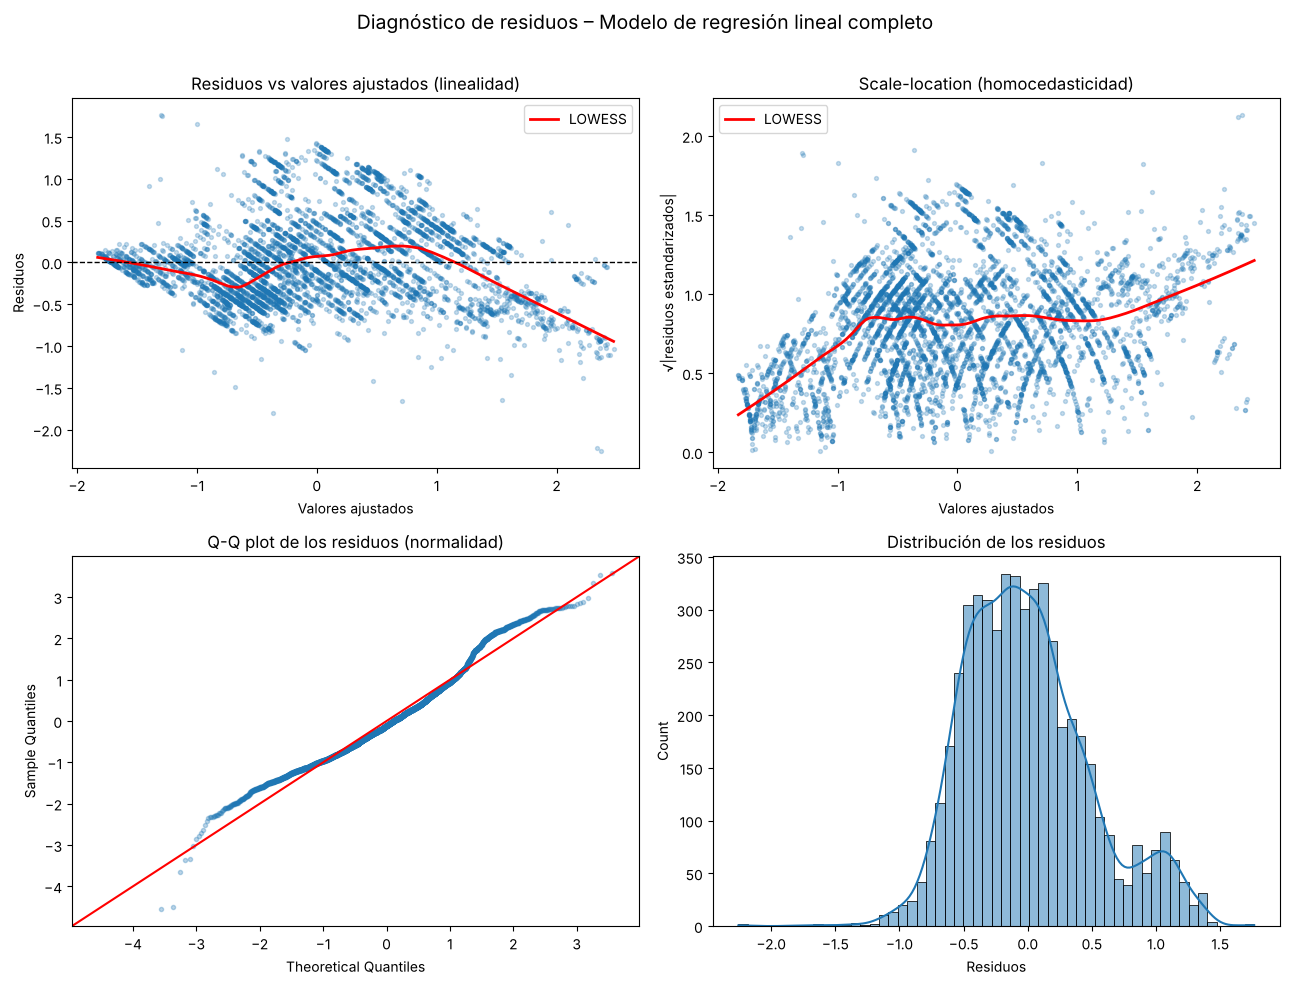

In [31]:
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.nonparametric.smoothers_lowess import lowess

def tabla_supuestos(modelo, X_const):
    """Contrastes formales de los supuestos de un modelo OLS de statsmodels."""
    resid = modelo.resid
    bp_stat, bp_p, _, _ = het_breuschpagan(resid, X_const)
    reset = linear_reset(modelo, power=2, use_f=True)
    jb_stat, jb_p, skew, kurt = jarque_bera(resid)
    return pd.DataFrame({
        'Supuesto': ['Linealidad', 'Homocedasticidad', 'Normalidad', 'Independencia'],
        'Contraste': ['RESET de Ramsey', 'Breusch-Pagan', 'Jarque-Bera', 'Durbin-Watson'],
        'Estadístico': [reset.fvalue, bp_stat, jb_stat, durbin_watson(resid)],
        'p-valor': [reset.pvalue, bp_p, jb_p, np.nan],
    }).round(4)

def graficos_supuestos(modelo, titulo):
    """Residuos vs ajustados, scale-location, Q-Q plot e histograma de residuos."""
    ajustados = modelo.fittedvalues
    resid = modelo.resid
    resid_std = modelo.get_influence().resid_studentized_internal

    fig, axes = plt.subplots(2, 2, figsize=(13, 10))

    ax = axes[0, 0]
    ax.scatter(ajustados, resid, alpha=0.25, s=8)
    curva = lowess(resid, ajustados, frac=0.3)
    ax.plot(curva[:, 0], curva[:, 1], color='red', lw=2, label='LOWESS')
    ax.axhline(0, color='black', ls='--', lw=1)
    ax.set_title('Residuos vs valores ajustados (linealidad)')
    ax.set_xlabel('Valores ajustados')
    ax.set_ylabel('Residuos')
    ax.legend()

    ax = axes[0, 1]
    raiz = np.sqrt(np.abs(resid_std))
    ax.scatter(ajustados, raiz, alpha=0.25, s=8)
    curva = lowess(raiz, ajustados, frac=0.3)
    ax.plot(curva[:, 0], curva[:, 1], color='red', lw=2, label='LOWESS')
    ax.set_title('Scale-location (homocedasticidad)')
    ax.set_xlabel('Valores ajustados')
    ax.set_ylabel('√|residuos estandarizados|')
    ax.legend()

    sm.qqplot(resid_std, line='45', ax=axes[1, 0], alpha=0.3, markersize=3)
    axes[1, 0].set_title('Q-Q plot de los residuos (normalidad)')

    ax = axes[1, 1]
    sns.histplot(resid, kde=True, ax=ax)
    ax.set_title('Distribución de los residuos')
    ax.set_xlabel('Residuos')

    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

def residuos_vs_predictores(modelo, X_datos, columnas, titulo):
    """Residuos frente a cada predictor numérico para detectar relaciones no lineales."""
    fig, axes = plt.subplots(1, len(columnas), figsize=(5 * len(columnas), 4.5))
    for ax, col in zip(axes, columnas):
        ax.scatter(X_datos[col], modelo.resid, alpha=0.25, s=8)
        if X_datos[col].nunique() <= 10:
            #Variable discreta: media de los residuos en cada nivel
            medias = modelo.resid.groupby(X_datos[col]).mean()
            ax.plot(medias.index, medias.values, color='red', lw=2, marker='o')
        else:
            curva = lowess(modelo.resid, X_datos[col], frac=0.3)
            ax.plot(curva[:, 0], curva[:, 1], color='red', lw=2)
        ax.axhline(0, color='black', ls='--', lw=1)
        ax.set_title(f'Residuos vs {col}')
        ax.set_xlabel(f'{col} (estandarizada)')
        ax.set_ylabel('Residuos')
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

def tabla_vif(X_const):
    """VIF de cada predictor (se excluye la constante)."""
    valores = X_const.values.astype(float)
    vif = pd.DataFrame({
        'Variable': X_const.columns,
        'VIF': [variance_inflation_factor(valores, i) for i in range(valores.shape[1])]
    })
    return vif[vif['Variable'] != 'const'].sort_values('VIF', ascending=False).round(2)

graficos_supuestos(model_reglin, 'Diagnóstico de residuos – Modelo de regresión lineal completo')

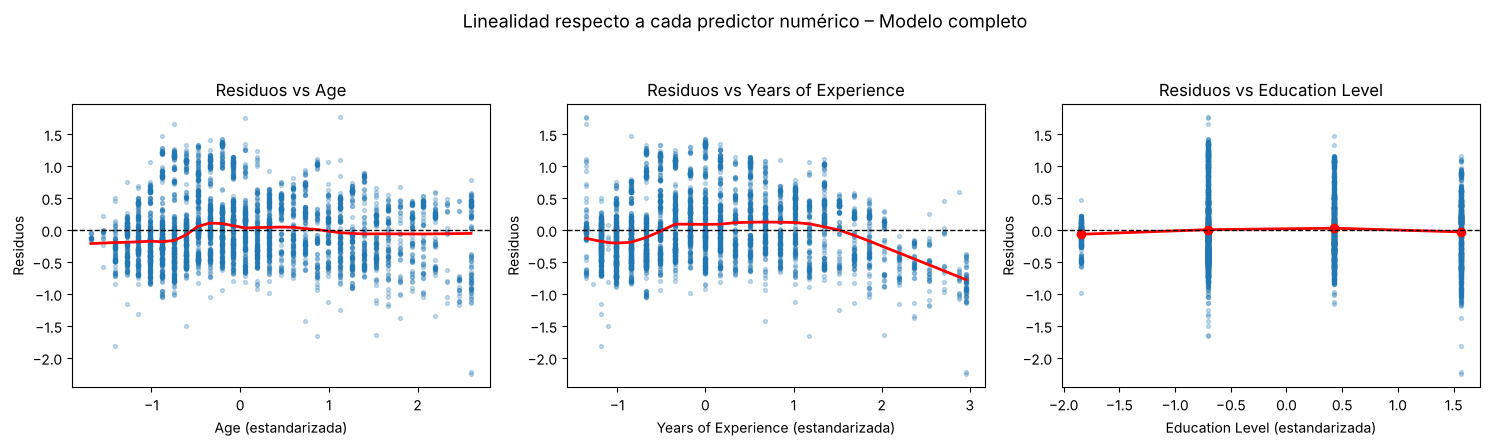

In [32]:
residuos_vs_predictores(model_reglin, X_train, ['Age', 'Years of Experience', 'Education Level'],
                        'Linealidad respecto a cada predictor numérico – Modelo completo')

In [33]:
print("Contrastes formales de los supuestos – Modelo completo")
display(tabla_supuestos(model_reglin, X_train_const))

print("\nFactor de inflación de la varianza (10 valores más altos)")
display(tabla_vif(X_train_const).head(10))

Contrastes formales de los supuestos – Modelo completo


,Supuesto,Contraste,Estadístico,p-valor
0,Linealidad,RESET de Ramsey,871.3967,0.0
1,Homocedasticidad,Breusch-Pagan,608.5994,0.0
2,Normalidad,Jarque-Bera,271.3386,0.0
3,Independencia,Durbin-Watson,2.0165,NaN



Factor de inflación de la varianza (10 valores más altos)


,Variable,VIF
26,Job_Category_Tech Engineering,27.10
22,Job_Category_Management,22.27
19,Job_Category_Data & Analytics,18.78
3,Years of Experience,10.08
23,Job_Category_Marketing & Sales,9.95
1,Age,9.87
18,Race_White,6.78
10,Race_Asian,5.77
7,Country_China,3.89
15,Race_Korean,3.82


**Interpretación de los supuestos**

- **Linealidad: no se cumple.** En el gráfico de residuos frente a valores ajustados la curva LOWESS no es plana: los residuos son negativos para los salarios previstos más bajos, positivos en la zona media y claramente negativos en los salarios previstos más altos. El gráfico frente a *Years of Experience* muestra el origen del problema: a partir de unos 1,5 desviaciones típicas por encima de la media de experiencia, los residuos caen de forma sistemática. Es decir, el salario no crece en línea recta con la experiencia, sino cada vez más despacio. En cambio, frente a *Age* y *Education Level* los residuos se mantienen centrados en cero, por lo que la falta de linealidad se concentra en la experiencia. El test RESET lo confirma (F = 871, p < 0,001).
- **Homocedasticidad: no se cumple.** En el gráfico *scale-location* la dispersión de los residuos es pequeña en los salarios más bajos, aumenta rápidamente hasta la zona media y vuelve a crecer en los salarios más altos. El test de Breusch-Pagan rechaza la varianza constante (LM = 608,6, p < 0,001). Los coeficientes siguen siendo insesgados, pero los errores estándar clásicos (y por tanto los p-valores) no son fiables.
- **Normalidad de los residuos: no se cumple del todo.** El Q-Q plot se separa de la diagonal en ambas colas y el histograma muestra un segundo grupo de residuos en torno a +1, es decir, un conjunto de empleados cuyo salario el modelo infravalora. Jarque-Bera rechaza la normalidad (JB = 271, asimetría 0,54, curtosis 3,30). Con más de 5.000 observaciones esto es lo menos grave, porque los coeficientes estimados son aproximadamente normales por el teorema central del límite.
- **Independencia: se cumple.** El Durbin-Watson de 2,02 indica que no hay autocorrelación en los residuos.
- **Multicolinealidad: moderada y localizada.** *Years of Experience* y *Age* tienen VIF cercanos a 10 porque están muy correlacionadas entre sí; esto explica que *Age* tenga coeficiente negativo: a igual experiencia, más edad no se traduce en más salario. Los VIF más altos (18–27) corresponden a las dummies de *Job_Category*, porque la categoría de referencia (*Administrative*) tiene muy pocos registros. Esto no afecta a las predicciones, pero sí infla los errores estándar de esas categorías y explica el Condition Number de 63.

### Corrección de los problemas detectados

Para la falta de linealidad añado un término cuadrático de **Years of Experience**, que permite que el salario crezca más despacio a medida que se acumula experiencia. Para la heterocedasticidad mantengo la estimación por mínimos cuadrados (los coeficientes siguen siendo insesgados) pero calculo errores estándar robustos **HC3**, que no asumen varianza constante, para que los p-valores sean fiables.

In [34]:
#Modelo con término cuadrático de la experiencia
X_train_q = X_train.copy()
X_test_q = X_test.copy()
X_train_q['Years of Experience^2'] = X_train_q['Years of Experience'] ** 2
X_test_q['Years of Experience^2'] = X_test_q['Years of Experience'] ** 2

X_train_q_const = sm.add_constant(X_train_q)
X_test_q_const = sm.add_constant(X_test_q)

model_quad = sm.OLS(y_train, X_train_q_const).fit()
model_quad_hc3 = sm.OLS(y_train, X_train_q_const).fit(cov_type='HC3')

#Comparación del modelo original y el corregido
def resumen_modelo(modelo, X_tr_const, X_te_const):
    tabla = tabla_supuestos(modelo, X_tr_const).set_index('Contraste')
    return {
        'R² train': modelo.rsquared,
        'R² ajustado': modelo.rsquared_adj,
        'R² test': r2_score(y_test, modelo.predict(X_te_const)),
        'p-valor RESET (linealidad)': tabla.loc['RESET de Ramsey', 'p-valor'],
        'p-valor Breusch-Pagan (homocedasticidad)': tabla.loc['Breusch-Pagan', 'p-valor'],
    }

comparacion = pd.DataFrame({
    'Modelo original': resumen_modelo(model_reglin, X_train_const, sm.add_constant(X_test)),
    'Modelo con experiencia²': resumen_modelo(model_quad, X_train_q_const, X_test_q_const),
}).round(4)
display(comparacion)

,Modelo original,Modelo con experiencia²
R² train,0.7550,0.7984
R² ajustado,0.7538,0.7973
R² test,0.7544,0.7849
p-valor RESET (linealidad),0.0000,0.4002
p-valor Breusch-Pagan (homocedasticidad),0.0000,0.0000


,Coeficiente,Error estándar clásico,Error estándar HC3,p-valor clásico,p-valor HC3
const,-0.1053,0.0769,0.0611,0.1709,0.0847
Age,-0.3122,0.0196,0.0259,0.0000,0.0000
Education Level,0.0878,0.0090,0.0101,0.0000,0.0000
Years of Experience,1.2067,0.0218,0.0324,0.0000,0.0000
Senior,-0.1989,0.0194,0.0176,0.0000,0.0000
Gender_Male,0.0579,0.0131,0.0132,0.0000,0.0000
Country_Canada,0.0052,0.0240,0.0241,0.8292,0.8299
Country_China,0.0013,0.0303,0.0307,0.9648,0.9653
Country_UK,-0.0221,0.0259,0.0250,0.3927,0.3760
Country_USA,-0.0100,0.0260,0.0265,0.7007,0.7065


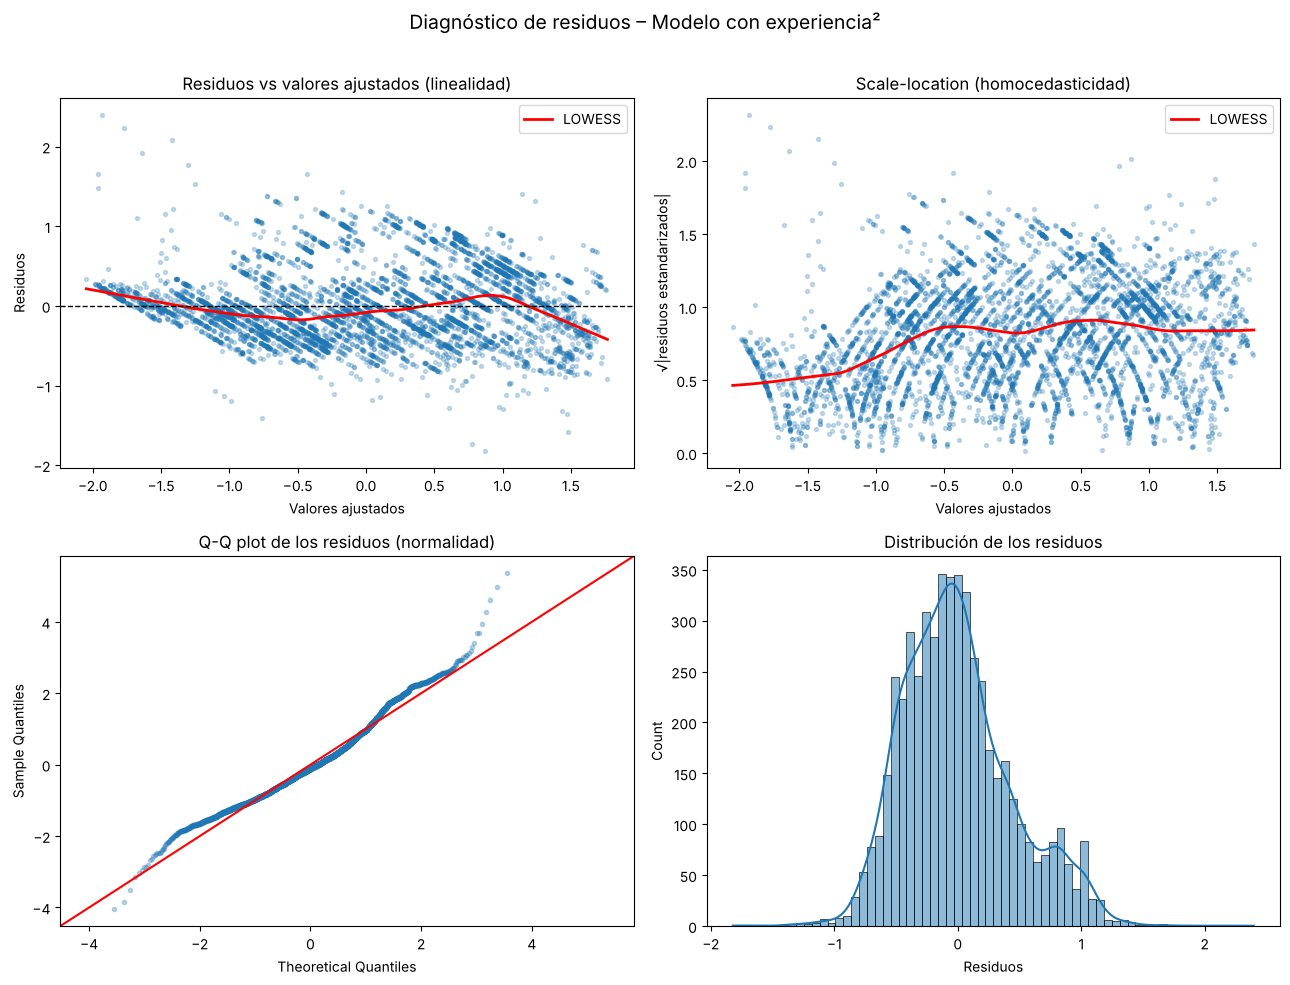

In [35]:
#Errores estándar clásicos frente a robustos (HC3)
coef_robustos = pd.DataFrame({
    'Coeficiente': model_quad.params,
    'Error estándar clásico': model_quad.bse,
    'Error estándar HC3': model_quad_hc3.bse,
    'p-valor clásico': model_quad.pvalues,
    'p-valor HC3': model_quad_hc3.pvalues,
}).round(4)
display(coef_robustos)

graficos_supuestos(model_quad, 'Diagnóstico de residuos – Modelo con experiencia²')

**Resultado de la corrección**

- Con el término cuadrático, el test RESET deja de ser significativo (p = 0,40): **el supuesto de linealidad pasa a cumplirse**. El coeficiente negativo de la experiencia al cuadrado (−0,20) confirma rendimientos decrecientes: cada año adicional de experiencia aporta menos salario que el anterior.
- El modelo mejora también en capacidad predictiva: el R² pasa de 0,755 a 0,798 en entrenamiento y de 0,754 a 0,785 en test, por lo que la mejora no es sobreajuste.
- La **heterocedasticidad se mantiene** (Breusch-Pagan, p < 0,001), lo que es esperable en salarios: los perfiles junior tienen salarios muy parecidos entre sí y los perfiles con más experiencia mucho más variables. Por eso utilizo los errores robustos HC3 para la inferencia.
- Con errores HC3, las conclusiones sobre *Age*, *Education Level*, *Years of Experience*, *Senior* y *Gender* no cambian (todas siguen siendo significativas). Sí cambian algunas categorías profesionales: *HR* (p = 0,007) y *Marketing & Sales* (p = 0,005) pasan a ser significativas, con salarios inferiores a la categoría de referencia, mientras que con los errores clásicos no lo eran. Ignorar la heterocedasticidad habría llevado a conclusiones distintas sobre estas categorías.

### Sesgo y supuestos del modelo de regresión lineal

El modelo obtiene un R² de 0,755 y un R² ajustado de 0,754, prácticamente idénticos. Esto significa que el modelo explica el 75% de la variabilidad del salario con las variables incluidas. El hecho de que ambos valores sean casi iguales, y que el R² en test (0,754) sea el mismo que en entrenamiento, indica que el modelo no está sobreajustado.

El estadístico F vale 620,9 con un p-valor de 0,00, lo que confirma que el modelo en su conjunto es estadísticamente significativo.

La variable **Years of Experience** muestra el efecto más fuerte y positivo, evidenciando que la experiencia laboral es el factor más determinante en la estructura salarial del dataset. **Education Level** también tiene un impacto positivo y significativo, mientras que **Age** y **Senior** aparecen con coeficiente negativo, lo que refleja su solapamiento con la experiencia (VIF cercanos a 10). En cuanto a **Gender**, ser hombre se asocia con un salario ligeramente mayor, una brecha estadísticamente significativa. Las categorías de trabajo muestran diferencias claras: Data & Analytics y Tech Engineering presentan salarios superiores a la categoría de referencia.

**¿Presenta sesgo el modelo?** No en el sentido de sobreajuste, pero sí presenta un **sesgo sistemático** en determinados rangos: al imponer una relación lineal con la experiencia, sobreestima los salarios más altos e infravalora los de la zona media, como muestra el gráfico de residuos frente a valores ajustados.

**¿Se cumplen los supuestos?** No todos. Tras comprobarlos de forma explícita:

| Supuesto | Resultado en el modelo original | Tras la corrección |
|---|---|---|
| Linealidad | No se cumple (RESET p < 0,001) | Se cumple con experiencia² (RESET p = 0,40) |
| Homocedasticidad | No se cumple (Breusch-Pagan p < 0,001) | Persiste; se corrige la inferencia con errores HC3 |
| Normalidad | No se cumple (Jarque-Bera p < 0,001) | Poco relevante con n > 5.000 |
| Independencia | Se cumple (Durbin-Watson 2,02) | Se cumple |
| Multicolinealidad | Moderada (Age/Experience y dummies de Job_Category) | No afecta a las predicciones |

El modelo original es útil para identificar patrones salariales, pero no es estadísticamente válido tal cual para hacer inferencia: la falta de linealidad introduce sesgo en las predicciones y la heterocedasticidad hace que los p-valores clásicos no sean fiables. Añadir el término cuadrático de la experiencia y usar errores robustos resuelve ambos problemas para la inferencia y mejora además el R² en test de 0,754 a 0,785.

### Validación cruzada (10 folds)

In [36]:
X_for_cv = sm.add_constant(X)

class StatsmodelsOLS(BaseEstimator, RegressorMixin):
    def fit(self, X_input, y):
        self.model_ = sm.OLS(y, X_input).fit()
        return self

    def predict(self, X_input):
        return self.model_.predict(X_input)

ols_wrapper = StatsmodelsOLS()
folds = 10

#Validación cruzada con R²
scores_r2 = cross_val_score(ols_wrapper, X_for_cv, y, cv=folds, scoring='r2')

#Validación cruzada con MSE
neg_mse_scorer = make_scorer(mean_squared_error, greater_is_better=False)
scores_mse = cross_val_score(ols_wrapper, X_for_cv, y, cv=folds, scoring=neg_mse_scorer)

print(f"R²  por fold: {np.round(scores_r2, 3)}")
print(f"R²  medio: {scores_r2.mean():.4f}  |  Std: {scores_r2.std():.4f}")
print()
print(f"MSE por fold (negativo): {-scores_mse}")
print(f"MSE medio: {-scores_mse.mean():.4f}  |  Std: {scores_mse.std():.4f}")


R²  por fold: [ 0.35  -0.942  0.581  0.644  0.648  0.712  0.855  0.833  0.836  0.813]
R²  medio: 0.5331  |  Std: 0.5133

MSE por fold (negativo): [0.57381559 0.97788323 0.33010625 0.26278265 0.29195425 0.19890185
 0.15922714 0.12179203 0.16116372 0.19833642]
MSE medio: 0.3276  |  Std: 0.2491


In [37]:
#Crear dataframe para boxplots
data_scores = pd.DataFrame({
    'MSE': scores_mse,
    'R2': scores_r2
})

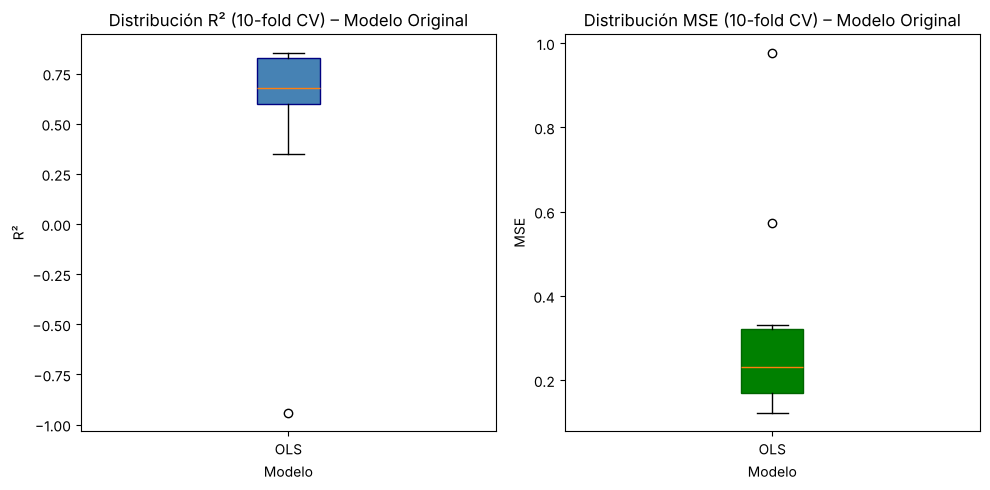

In [38]:
#Gráficos boxplot de los resultados de validación cruzada
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].boxplot(scores_r2, vert=True, patch_artist=True,
                boxprops=dict(facecolor='steelblue', color='navy'))
axes[0].set_title('Distribución R² (10-fold CV) – Modelo Original')
axes[0].set_ylabel('R²')
axes[0].set_xlabel('Modelo')
axes[0].set_xticks([1], ['OLS'])

axes[1].boxplot(-scores_mse, vert=True, patch_artist=True,
                boxprops=dict(facecolor='green', color='darkgreen'))
axes[1].set_title('Distribución MSE (10-fold CV) – Modelo Original')
axes[1].set_ylabel('MSE')
axes[1].set_xlabel('Modelo')
axes[1].set_xticks([1], ['OLS'])

plt.tight_layout()
plt.show()


### Varianza en la validación cruzada

A la vista de los resultados de la validación cruzada, si existen problemas de varianza en el modelo entrenado, y esto se puede justificar directamente con los valores obtenidos tanto en R² como en MSE.

Los valores y los boxplots evidencian una gran dispersión entre folds, incluyendo casos donde el modelo presenta un rendimiento muy pobre ya que hay un valor R² negativo y un MSE elevado.

Esto indica que el modelo no generaliza de forma estable y su desempeño depende fuertemente del subconjunto de datos utilizado en cada partición. La causa principal puede ser la presencia de outliers severos, distribuciones sesgadas, multicolinealidad o variables categóricas desbalanceadas, que afectan de manera desigual a cada fold de la validación cruzada.


## 8. Selección de variables con el método Forward

Busco un modelo con menos variables que prediga igual o mejor que el modelo completo.

In [39]:
#Selección Forward de variables
lr_sklearn = LinearRegression()

sfs = SFS(
    lr_sklearn,
    k_features='best',
    forward=True,
    floating=False,
    scoring='r2',
    cv=5,
    n_jobs=-1
)

sfs.fit(X_train, y_train)

print(f"Número de variables seleccionadas: {len(sfs.k_feature_names_)}")
print(f"Variables seleccionadas: {list(sfs.k_feature_names_)}")
print(f"R² de la iteración óptima: {sfs.k_score_:.4f}")

Número de variables seleccionadas: 18
Variables seleccionadas: ['Age', 'Education Level', 'Years of Experience', 'Senior', 'Gender_Male', 'Country_China', 'Race_Australian', 'Race_Chinese', 'Race_Welsh', 'Race_White', 'Job_Category_Data & Analytics', 'Job_Category_Finance & Operations', 'Job_Category_HR', 'Job_Category_Management', 'Job_Category_Marketing & Sales', 'Job_Category_Other', 'Job_Category_Product & Project', 'Job_Category_Tech Engineering']
R² de la iteración óptima: 0.7524


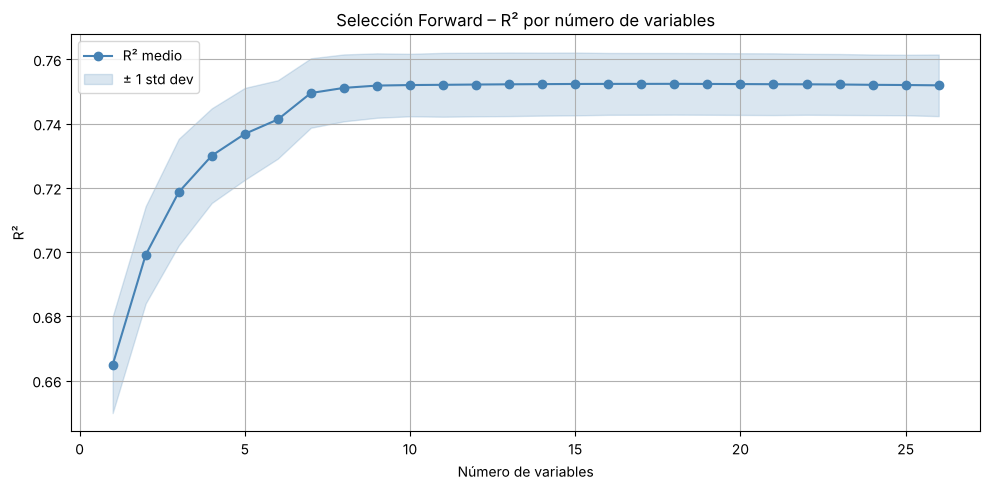

In [40]:
#Gráfico de performance de la selección en cada iteración
metric_dict = sfs.get_metric_dict()

#Extraer número de variables, R² medio y desviación estándar de cada iteración
n_features = sorted(metric_dict.keys())
avg_scores  = [metric_dict[k]['avg_score'] for k in n_features]
std_scores  = [metric_dict[k]['std_dev']   for k in n_features]

plt.figure(figsize=(10, 5))
plt.plot(n_features, avg_scores, marker='o', linestyle='-', color='steelblue', label='R² medio')
plt.fill_between(n_features,
                 [a - s for a, s in zip(avg_scores, std_scores)],
                 [a + s for a, s in zip(avg_scores, std_scores)],
                 alpha=0.2, color='steelblue', label='± 1 std dev')
plt.title('Selección Forward – R² por número de variables')
plt.xlabel('Número de variables')
plt.ylabel('R²')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Variables seleccionadas por el método Forward

El método de selección Forward ha seleccionada 18 variables de las 26 disponibles, eliminando 8 variables que no aportaban mejor significativa al modelo. Las variables descartadas fueron: Country_Canada, Country_UK, Country_USA, Race_Asian, Race_Black, Race_Hispanic, Race_Korean y Race_Mixed.

El hecho de que el método haya seleccionado 18 variables indica que, según la validación cruzada, la mayoría de las variables aportan información útil al modelo. El dataset contiene muchos predictores con contribuciones pequeñas pero consistentes, y el algoritmo considera que eliminarlos empeora el rendimiento. Además, el R² obtenido (0.7524) es muy similar al del modelo original, lo que confirma que no existe un subconjunto pequeño de variables que mejore el rendimiento: el modelo completo ya estaba capturando bien la estructura de los datos.

Mirando el gráfico, se puede observar que con 10 variables ya alcanza ~0.75, lo que indica que un subconjunto pequeño de variables captura la mayor parte de la varianza del salario. A partir de la iteración 10 aproximadamente, la curva se aplana completamente y añadir más variables apenas mejora el R² en menos de 0.002 puntos. El algoritmo selecciona 18 como punto óptimo porque es donde se maximiza el R² medio de forma global, pero en la práctica la diferencia respecto a un modelo de 10 variables es mínima.

### Modelo con las variables seleccionadas

In [41]:
#Subconjunto de variables seleccionadas
selected_features = list(sfs.k_feature_names_)
X_sel = X[selected_features]

#Train/Test con las variables seleccionadas
X_sel_train, X_sel_test, y_sel_train, y_sel_test = train_test_split(
    X_sel, y, test_size=0.2, random_state=42
)

#Entrenar el modelo
X_sel_train_const = sm.add_constant(X_sel_train)
model_sel = sm.OLS(y_sel_train, X_sel_train_const).fit()

print(model_sel.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.755
Model:                            OLS   Adj. R-squared:                  0.754
Method:                 Least Squares   F-statistic:                     896.8
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:45:55   Log-Likelihood:                -3777.7
No. Observations:                5265   AIC:                             7593.
Df Residuals:                    5246   BIC:                             7718.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const 

In [42]:
#Comprobación de supuestos del modelo con selección Forward
display(tabla_supuestos(model_sel, X_sel_train_const))
display(tabla_vif(X_sel_train_const).head(10))

,Supuesto,Contraste,Estadístico,p-valor
0,Linealidad,RESET de Ramsey,878.0091,0.0
1,Homocedasticidad,Breusch-Pagan,604.2886,0.0
2,Normalidad,Jarque-Bera,273.1893,0.0
3,Independencia,Durbin-Watson,2.0154,NaN


,Variable,VIF
18,Job_Category_Tech Engineering,27.05
14,Job_Category_Management,22.24
11,Job_Category_Data & Analytics,18.77
3,Years of Experience,10.07
15,Job_Category_Marketing & Sales,9.94
1,Age,9.86
13,Job_Category_HR,2.67
17,Job_Category_Product & Project,2.38
2,Education Level,1.95
16,Job_Category_Other,1.92


El modelo reducido obtenido tras la selección Forward mantiene la misma capacidad explicativa que el modelo completo, con un R² de 0,755 y un R² ajustado de 0,754, lo que indica que las 18 variables seleccionadas explican alrededor del 75% de la variabilidad del salario sin pérdida apreciable de rendimiento.

La mayoría de los coeficientes son estadísticamente significativos y conservan relaciones coherentes con la lógica del fenómeno, mientras que algunas variables muestran efectos menos claros pero fueron retenidas porque contribuyen marginalmente al ajuste global.

Al comprobar los supuestos, el modelo reducido presenta los mismos problemas que el completo: falta de linealidad (RESET p < 0,001), heterocedasticidad (Breusch-Pagan p < 0,001) y residuos no normales, mientras que no hay autocorrelación (Durbin-Watson 2,02). Era de esperar, porque la selección elimina variables de país y raza pero mantiene la experiencia en forma lineal y las dummies de categoría profesional, que son el origen de estos problemas. Por tanto, la corrección aplicada al modelo completo (experiencia al cuadrado y errores HC3) sería igualmente necesaria aquí. En conjunto, la selección de variables simplifica el modelo sin sacrificar capacidad predictiva.

In [43]:
#Validación cruzada con variables seleccionadas
X_sel_for_cv = sm.add_constant(X_sel)
ols_wrapper_sel = StatsmodelsOLS()

scores_r2_sel  = cross_val_score(ols_wrapper_sel, X_sel_for_cv, y, cv=10, scoring='r2')
scores_mse_sel = cross_val_score(ols_wrapper_sel, X_sel_for_cv, y, cv=10, scoring=neg_mse_scorer)

print(f"R²  medio (Forward): {scores_r2_sel.mean():.4f}  |  Std: {scores_r2_sel.std():.4f}")
print(f"MSE medio (Forward): {-scores_mse_sel.mean():.4f}  |  Std: {scores_mse_sel.std():.4f}")

R²  medio (Forward): 0.5340  |  Std: 0.5127
MSE medio (Forward): 0.3269  |  Std: 0.2488


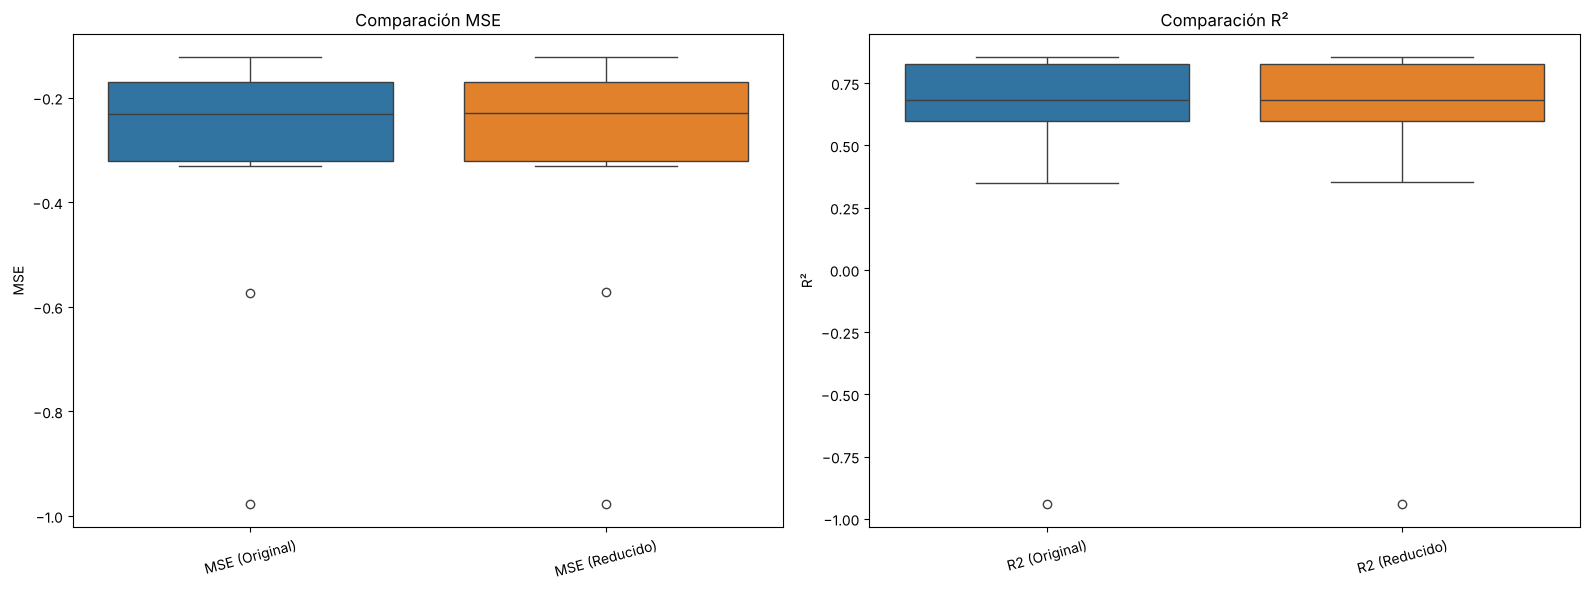

In [44]:
#Crear DataFrame comparativo
data_compare = pd.DataFrame({
    'MSE (Original)': scores_mse,
    'MSE (Reducido)': scores_mse_sel,
    'R2 (Original)': scores_r2,
    'R2 (Reducido)': scores_r2_sel
})

#Crear figura con dos subplots
fig, axes = plt.subplots(1, 2, figsize=(16,6))

#Boxplot MSE
sns.boxplot(data=data_compare[['MSE (Original)', 'MSE (Reducido)']], ax=axes[0])
axes[0].set_title("Comparación MSE")
axes[0].set_ylabel("MSE")
axes[0].tick_params(axis='x', rotation=15)

#Boxplot R²
sns.boxplot(data=data_compare[['R2 (Original)', 'R2 (Reducido)']], ax=axes[1])
axes[1].set_title("Comparación R²")
axes[1].set_ylabel("R²")
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

### Modelo completo frente a modelo Forward

Comparando ambos modelos podemos ver que ofrecen prácticamente el mismo rendimmiento, pero el modelo reducido lo hace con menos variables y mayor estabilidad.

El modelo original explica alrededor del 75% de la variabilidad del salario y el modelo reducido alcanza el mismo R² con un MSE igual.

Además, los boxplots de ambos modelos muestran distribuciones casi idénticas, lo que confirma que la capacidad de generalización no se ve afectada por la reducción de variables.

El condition number es casi el mismo en ambos modelos (63 vs 62.9). Esto confirma que el Forward no ha resuelto en absoluto el problema de multicolinealidad, porque las variables que la generan han permanecido en el modelo seleccionado.

La selección forward reduce la complejidad sin pérdida apreciable de capacidad explicativa, lo que mejora la interpretabilidad, pero persisten problemas detectados en ambos modelos.

Para el objetivo del proyecto el modelo forward es preferible por su parsimonia y similar rendimiento predictivo, pero debe reforzarse.

## 9. Regresión sobre componentes principales (PCA)

En lugar de seleccionar variables, reduzco la dimensionalidad con un análisis de componentes principales.

In [45]:
#Analisis de PCA a partir del conjunto de variables predictoras

#Estandarizar antes del PCA
scaler_pca = StandardScaler()
X_scaled_pca = scaler_pca.fit_transform(X)

pca = PCA()
pca.fit(X_scaled_pca)

#Varianza explicada acumulada
explained_ratio = pca.explained_variance_ratio_
cum_var = np.cumsum(explained_ratio)

#Número de componentes para distintos umbrales
n_comp_90 = np.argmax(cum_var >= 0.90) + 1
n_comp_95 = np.argmax(cum_var >= 0.95) + 1
n_comp_99 = np.argmax(cum_var >= 0.99) + 1

print(f"Componentes para explicar el 90% de varianza: {n_comp_90}")
print(f"Componentes para explicar el 95% de varianza: {n_comp_95}")
print(f"Componentes para explicar el 99% de varianza: {n_comp_99}")
print()

#Tabla de varianza explicada por componente
data_var = pd.DataFrame({
    'Componente':     range(1, len(explained_ratio) + 1),
    'Autovalor':      np.round(pca.explained_variance_, 4),
    'Varianza (%)':   np.round(explained_ratio * 100, 2),
    'Acumulada (%)':  np.round(cum_var * 100, 2)
})
print(data_var.to_string(index=False))

Componentes para explicar el 90% de varianza: 17
Componentes para explicar el 95% de varianza: 19
Componentes para explicar el 99% de varianza: 22

 Componente  Autovalor  Varianza (%)  Acumulada (%)
          1     2.8415         10.93          10.93
          2     2.1158          8.14          19.06
          3     1.9117          7.35          26.42
          4     1.7579          6.76          33.18
          5     1.5845          6.09          39.27
          6     1.3755          5.29          44.56
          7     1.3355          5.14          49.69
          8     1.1849          4.56          54.25
          9     1.1636          4.47          58.73
         10     1.1596          4.46          63.19
         11     1.0895          4.19          67.37
         12     1.0498          4.04          71.41
         13     1.0434          4.01          75.42
         14     1.0142          3.90          79.32
         15     0.9943          3.82          83.15
         16     0.97

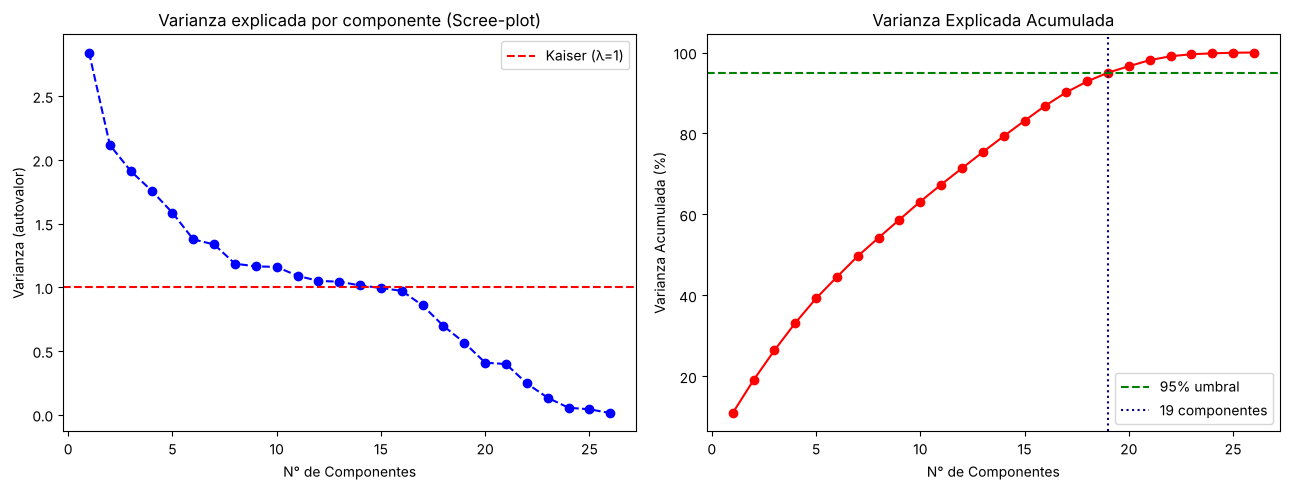

In [46]:
#Scree-plot - varianza explicada acumulada

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

#Varianza por componente
axes[0].plot(range(1, len(pca.explained_variance_) + 1),
             pca.explained_variance_, marker='o', linestyle='--', color='b')
axes[0].axhline(y=1, color='r', linestyle='--', label='Kaiser (λ=1)')
axes[0].set_title('Varianza explicada por componente (Scree-plot)')
axes[0].set_xlabel('N° de Componentes')
axes[0].set_ylabel('Varianza (autovalor)')
axes[0].legend()

#Varianza acumulada
axes[1].plot(range(1, len(cum_var) + 1), cum_var * 100,
             marker='o', linestyle='-', color='r')
axes[1].axhline(y=95, color='green', linestyle='--', label='95% umbral')
axes[1].axvline(x=n_comp_95, color='navy', linestyle=':', label=f'{n_comp_95} componentes')
axes[1].set_title('Varianza Explicada Acumulada')
axes[1].set_xlabel('N° de Componentes')
axes[1].set_ylabel('Varianza Acumulada (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

### Componentes necesarias para el 95% de la varianza

Para explicar el 95% de la varianza acumulada se necesitan 19 componentes principales. Esto se deduce de la tabla de varianza acumulada.

El scree plot confirma que no existe un "codo" pronunciado que indique una reducción drástica de dimensionalidad. El criterio de Kaiser sugiere mantener 13 o 14 componentes.

### Modelo sobre las componentes principales

In [47]:
#Proyectar los datos sobre las n_comp_95 componentes
pca_final = PCA(n_components=n_comp_95)
X_pca = pca_final.fit_transform(X_scaled_pca)

#Crear DataFrame de componentes
cols_pca = [f'PC{i+1}' for i in range(n_comp_95)]
X_pca_df = pd.DataFrame(X_pca, columns=cols_pca, index=X.index)

#Train/Test split
X_pca_train, X_pca_test, y_pca_train, y_pca_test = train_test_split(
    X_pca_df, y, test_size=0.2, random_state=42
)

#Entrenar regresión lineal sobre las componentes PCA
X_pca_train_const = sm.add_constant(X_pca_train)
model_pca = sm.OLS(y_pca_train, X_pca_train_const).fit()

print(model_pca.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.713
Model:                            OLS   Adj. R-squared:                  0.712
Method:                 Least Squares   F-statistic:                     686.4
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:45:56   Log-Likelihood:                -4189.6
No. Observations:                5265   AIC:                             8419.
Df Residuals:                    5245   BIC:                             8551.
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0009      0.007      0.119      0.9

In [48]:
ols_wrapper_pca = StatsmodelsOLS()

scores_r2_pca  = cross_val_score(ols_wrapper_pca, X_pca_df, y, cv=10, scoring='r2')
scores_mse_pca = cross_val_score(ols_wrapper_pca, X_pca_df, y, cv=10, scoring=neg_mse_scorer)

print(f"R²  por fold (PCA): {np.round(scores_r2_pca, 3)}")
print(f"R²  medio (PCA): {scores_r2_pca.mean():.4f}  |  Std: {scores_r2_pca.std():.4f}")
print()
print(f"MSE por fold (PCA, negativo): {np.round(-scores_mse_pca, 3)}")
print(f"MSE medio (PCA): {-scores_mse_pca.mean():.4f}  |  Std: {scores_mse_pca.std():.4f}")

R²  por fold (PCA): [ 0.265 -1.021  0.887  0.825  0.859  0.632  0.846  0.789  0.732  0.726]
R²  medio (PCA): 0.5539  |  Std: 0.5520

MSE por fold (PCA, negativo): [0.649 1.017 0.089 0.13  0.117 0.255 0.17  0.154 0.262 0.29 ]
MSE medio (PCA): 0.3133  |  Std: 0.2798


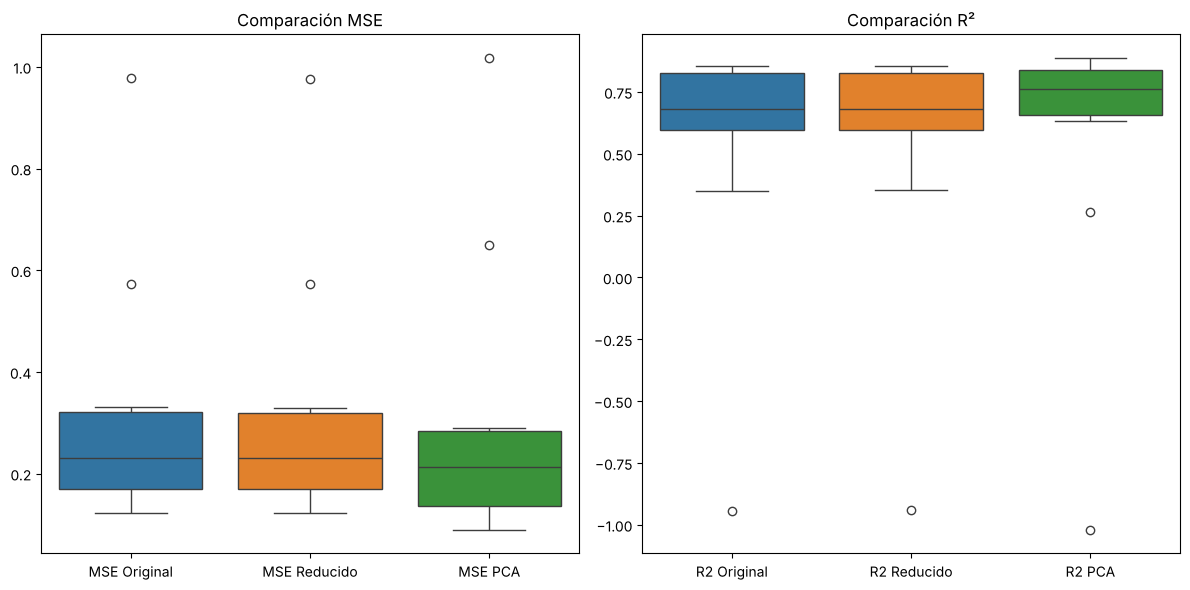

In [49]:
#Apoyo gráfico para interpretar la validación
data_compare_all = pd.DataFrame({
    'MSE Original': -scores_mse,
    'MSE Reducido': -scores_mse_sel,
    'MSE PCA': -scores_mse_pca,
    'R2 Original': scores_r2,
    'R2 Reducido': scores_r2_sel,
    'R2 PCA': scores_r2_pca
})

fig, axes = plt.subplots(1, 2, figsize=(12,6))

sns.boxplot(data=data_compare_all[['MSE Original','MSE Reducido','MSE PCA']], ax=axes[0])
axes[0].set_title("Comparación MSE")

sns.boxplot(data=data_compare_all[['R2 Original','R2 Reducido','R2 PCA']], ax=axes[1])
axes[1].set_title("Comparación R²")

plt.tight_layout()
plt.show()

### Comparación de los tres modelos de regresión

Tras comparar los tres modelos entrenados, se observan diferencias importantes. El análisis del Condition Number muestra que el modelo PCA es el que presenta el valor más bajo, 2,27, frente a los valores cercanos a 63 de los modelos original y reducido. Este resultado se explica porque PCA transforma las variables originales en componentes principales ortogonales (incorreladas entre sí), eliminando completamente la multicolinealidad y generando una matriz de diseño mucho más estable desde el punto de vista numérico.

Sin embargo, a pesar de esta ventaja, el modelo PCA no resulta el más adecuado para el caso de uso. Su poder explicativo es el más bajo de los tres (R² = 0,713 frente a 0,755), porque las componentes que retienen el 95% de la varianza de las predictoras no tienen por qué ser las más relacionadas con el salario: PCA no tiene en cuenta la variable objetivo al construirlas. Además, pierde la interpretabilidad, ya que cada componente es una combinación de todas las variables originales.

En validación cruzada los tres modelos se comportan de forma muy parecida (R² medio de 0,53 en el original y el reducido y de 0,55 en el PCA, con una desviación de alrededor de 0,5 en los tres) y los mismos folds dan malos resultados en todos ellos. Esto indica que la inestabilidad no depende del modelo sino de cómo se reparten los datos entre los folds.

El modelo reducido mediante selección Forward es el más apropiado, ya que conserva la interpretabilidad de las variables originales, mantiene el mismo nivel de explicación del salario que el modelo completo con menos variables y, a diferencia del PCA, permite aplicar directamente las correcciones de linealidad y heterocedasticidad vistas en el modelo completo.

## 10. Regresión logística: predicción de *Gender*

Con el mismo conjunto de datos cambio de objetivo: clasificar cada registro como *Female* (0) o *Male* (1). *Salary* pasa a ser una predictora más y mantengo la imputación de nulos hecha en la preparación.

In [50]:
#Binarizar la variable objetivo Gender
#Female = 0, Male = 1
data_log = data.copy()
data_log['Gender_bin'] = (data_log['Gender']).map({'Female': 0, 'Male': 1})

print("Distribución de Gender binarizado:")
print(data_log['Gender_bin'].value_counts())

Distribución de Gender binarizado:
Gender_bin
1    3654
0    2928
Name: count, dtype: int64


### Preparación de los datos para la regresión logística

In [51]:
data_log_temp = data_log.copy()
if 'Gender' in data_log_temp.columns:
    data_log_temp = data_log_temp.drop(columns=['Gender'])

data_encoded = pd.get_dummies(
    data_log_temp,
    columns=['Country', 'Race', 'Job_Category'],
    drop_first=True,
    dtype=int
)
data = data_encoded.copy()

In [52]:
cols_to_remove = [
    'Gender_bin',
    'Job Title',
    'Gender_Male'
]

X = data.drop(columns=[col for col in cols_to_remove if col in data.columns])
y = data['Gender_bin']

In [53]:
#Identificar las columnas numéricas
numeric_features = X.columns.tolist()

#Normalización
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features)
    ],
    remainder='passthrough'
)

print("Número de columnas en X:", len(X.columns))
print("Primeras columnas de X:", X.columns[:20])

Número de columnas en X: 26
Primeras columnas de X: Index(['Age', 'Education Level', 'Years of Experience', 'Salary', 'Senior',
       'Country_Canada', 'Country_China', 'Country_UK', 'Country_USA',
       'Race_Asian', 'Race_Australian', 'Race_Black', 'Race_Chinese',
       'Race_Hispanic', 'Race_Korean', 'Race_Mixed', 'Race_Welsh',
       'Race_White', 'Job_Category_Data & Analytics',
       'Job_Category_Finance & Operations'],
      dtype='str')


In [54]:
#Estandarizar
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns, index=X.index)
X_scaled_const = sm.add_constant(X_scaled)

### Análisis factorial previo

Entrenar la regresión logística directamente con todas las dummies da problemas de convergencia por colinealidad. Un análisis factorial ayuda a entender las variables latentes y a reducir la dimensionalidad.

In [55]:
#Preparar variables predictoras para el análisis factorial
data_log_prep = pd.get_dummies(data_log,
                               columns=['Country', 'Race', 'Job_Category'],
                               drop_first=False)

#Eliminar columnas no numéricas y la variable objetivo
cols_to_drop = ['Gender', 'Job Title', 'Gender_bin']
data_log_num = data_log_prep.drop(columns=cols_to_drop, errors='ignore')
bool_c = data_log_num.select_dtypes(include='bool').columns
data_log_num[bool_c] = data_log_num[bool_c].astype(int)
data_log_num = data_log_num.apply(pd.to_numeric, errors='coerce').dropna()

#Estandarizar
scaler_fa = StandardScaler()
X_fa_scaled = scaler_fa.fit_transform(data_log_num)
X_fa_df = pd.DataFrame(X_fa_scaled, columns=data_log_num.columns)

print("Shape del dataset para análisis factorial:", X_fa_df.shape)

Shape del dataset para análisis factorial: (6582, 29)


In [56]:
#Ajustar PCA con todas las componentes posibles
pca = PCA()
pca.fit(X_scaled)

#Autovalores
eigenvalues = pca.explained_variance_

#Autovectores
eigenvectors = pca.components_

#Varianza explicada y acumulada
explained = pca.explained_variance_ratio_
cum_explained = np.cumsum(explained)

#Tabla resumen
df_pca = pd.DataFrame({
    'Componente': np.arange(1, len(explained) + 1),
    'Autovalor': eigenvalues,
    'Varianza Explicada (%)': explained * 100,
    'Varianza Acumulada (%)': cum_explained * 100,
    'Autovector': eigenvectors.tolist()
})

print(df_pca)

    Componente  Autovalor  Varianza Explicada (%)  Varianza Acumulada (%)  \
0            1   3.557135               13.679211               13.679211   
1            2   2.115868                8.136718               21.815930   
2            3   1.911994                7.352708               29.168637   
3            4   1.757867                6.759998               35.928635   
4            5   1.575086                6.057101               41.985737   
5            6   1.375514                5.289636               47.275372   
6            7   1.330985                5.118396               52.393768   
7            8   1.186469                4.562650               56.956418   
8            9   1.160543                4.462951               61.419368   
9           10   1.109393                4.266248               65.685617   
10          11   1.078494                4.147422               69.833038   
11          12   1.050273                4.038896               73.871935   

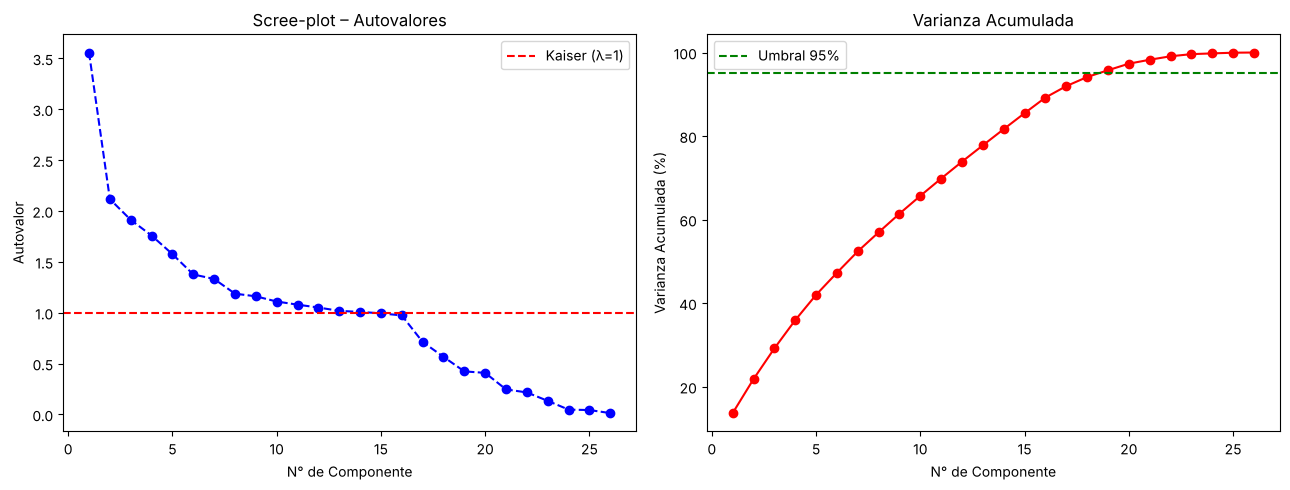

In [57]:
#Scree-plot del análisis factorial
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(range(1, len(eigenvalues) + 1), eigenvalues, marker='o', linestyle='--', color='b')
axes[0].axhline(y=1, color='r', linestyle='--', label='Kaiser (λ=1)')
axes[0].set_title('Scree-plot – Autovalores')
axes[0].set_xlabel('N° de Componente')
axes[0].set_ylabel('Autovalor')
axes[0].legend()

axes[1].plot(range(1, len(cum_explained) + 1), cum_explained * 100, marker='o', color='r')
axes[1].axhline(y=95, color='green', linestyle='--', label='Umbral 95%')
axes[1].set_title('Varianza Acumulada')
axes[1].set_xlabel('N° de Componente')
axes[1].set_ylabel('Varianza Acumulada (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

### Varianza explicada y criterio de Kaiser

Según los resultados obtenidos, el 95% de la varianza acumulda se alcanza únicamente cuando se incorpora 19 componentes principales.

Por otro lado, si aplicamos el criterio de Kaiser, que indica conservar únicamente los factores con autovalor mayor que 1, vemos en la tabla que los autovalores superiores a ese umbral aparecen solo en las primeras 14 componentes, y a partir de ese punto los autovalores caen por debajo de 1. Además, el scree‑plot confirma visualmente este comportamiento.

Esto significa que, según Kaiser, deberían conservarse esas 14 componentes, ya que todas las restantes presentan autovalores inferiores a 1 y, por tanto, no aportan suficiente varianza individual para ser consideradas factores relevantes.

### Cargas factoriales según el criterio de Kaiser

In [58]:
#Número de factores según Kaiser
n_kaiser = int((eigenvalues >= 1).sum())
print(f"Factores según criterio de Kaiser (λ ≥ 1): {n_kaiser}")


Factores según criterio de Kaiser (λ ≥ 1): 14


In [59]:
#Análisis Factorial con factor_analyzer
fa = FactorAnalyzer(n_factors=n_kaiser, rotation='varimax')
fa.fit(X_fa_df)

#Matriz de cargas factoriales
loadings = pd.DataFrame(
    fa.loadings_,
    index=data_log_num.columns,
    columns=[f'Factor_{i+1}' for i in range(n_kaiser)]
)

print("Cargas Factoriales (todos los factores según Kaiser):")
print(loadings.round(3))

Cargas Factoriales (todos los factores según Kaiser):
                                   Factor_1  Factor_2  Factor_3  Factor_4  \
Age                                   0.937     0.052    -0.006    -0.001   
Education Level                       0.660     0.019     0.006    -0.009   
Years of Experience                   0.956     0.094    -0.003    -0.004   
Salary                                0.788     0.044    -0.008    -0.011   
Senior                                0.386    -0.138     0.018    -0.001   
Country_Australia                    -0.011    -0.008    -0.851     0.214   
Country_Canada                        0.004    -0.004     0.214    -0.853   
Country_China                         0.012     0.002     0.212     0.212   
Country_UK                            0.013    -0.001     0.216     0.214   
Country_USA                          -0.018     0.011     0.218     0.217   
Race_African American                -0.006    -0.001     0.060     0.060   
Race_Asian            

La matriz de cargas factoriales revela que los primeros factores concentran la mayor parte de la estructura significativa del dataset. El primer factor agrupa variables como edad, nivel educativo, años de experiencia y salario, lo que sugiere una dimensión de trayectoria profesional y nivel socioeconómico. El segundo factor está fuertemente asociado a la categoría “Tech Engineering”, indicando una dimensión de especialización ocupacional. Otros factores iniciales recogen combinaciones de categorías laborales y niveles de seniority.

Sin embargo, a medida que avanzan los factores, las cargas factoriales se vuelven extremadamente pequeñas, lo que indica que la mayoría de los factores seleccionados por el criterio de Kaiser no son interpretables y solo representan descomposiciones matemáticas de variabilidad residual. Esto confirma que, aunque Kaiser selecciona un número muy elevado de factores, la estructura real del dataset está dominada por un conjunto reducido de dimensiones latentes, y que el espacio original de predictores presenta una fuerte redundancia y multicolinealidad.

### Interpretación de los factores

En base a los factores seleccionados mediante el método de Kaiser, la matriz de cargas factoriales muestra que la estructura latente del dataset está fuertemente concentrada en los primeros componentes, mientras que los restantes reflejan sobre todo descomposición matemática de la variabilidad.

El **Factor 1** muestra cargas muy altas en *Age*, *Education Level*, *Years of Experience* y *Salary*, lo que indica que representa una dimensión clara asociada a la trayectoria profesional acumulada. Las personas con mayor edad, más años de experiencia y mayor nivel educativo tienden a presentar salarios más altos. *Senior* también carga positivamente, aunque con menor intensidad, reforzando la idea de que este factor captura el nivel general de desarrollo profesional.

El **Factor 2** está dominado por dos cargas muy elevadas y opuestas: *Job_Category_Management* (0.938) y *Job_Category_Tech Engineering* (–0.752)

Esto indica que este factor representa una oposición entre perfiles de gestión y perfiles técnicos de ingeniería. Las demás variables tienen cargas muy pequeñas, por lo que este factor captura exclusivamente la segmentación entre roles de management y roles técnicos.

El **Factor 3** presenta cargas muy altas en: *Country_Australia* (–0.851), *Country_Canada* (0.214), *Race_Australian* (–0.64) y *Race_Black* (–0.639).

Las cargas indican que este factor captura una dimensión geográfica y étnica, donde los individuos de origen australiano (tanto país como raza) se agrupan fuertemente en un extremo del factor. La presencia de Race_Black también sugiere una diferenciación étnica adicional.

El **Factor 4** captura una dimensión geográfica, pero con una estructura distinta: separa a Canadá del resto de países anglosajones. La presencia de Race_Black refuerza la idea de que este factor también recoge variabilidad étnica.

El **Factor 5** presenta cargas muy elevadas en: *Race_Asian* (–0.949) y *Race_White* (0.642). Esto indica una dimensión étnica muy marcada, donde los perfiles asiáticos se sitúan en un extremo y los perfiles blancos en el otro.

El **Factor 7** está dominado por Job_Category_Data & Analytics (0.985). Esto indica que este factor representa una dimensión ocupacional específica, aislando claramente a los perfiles de Data & Analytics del resto de categorías laborales.

Los **Factores 8 a 14** muestran cargas pequeñas o moderadas, combinaciones dispersas de países, razas y categorías laborales.

Esto indica que estos factores representan variabilidad residual, segmentaciones menores o ruido estructural propio de datasets con muchas variables categóricas codificadas como dummies.


### Modelo de 2 factores con rotación varimax

In [60]:
#Análisis Factorial con 2 factores
fa2 = FactorAnalyzer(n_factors=2)
fa2.fit(X_fa_df)

#Cargas factoriales para los 2 factores
loadings2 = pd.DataFrame(
    fa2.loadings_,
    index=data_log_num.columns,
    columns=['Factor_1', 'Factor_2']
)

print("Cargas Factoriales:")
print(loadings2.round(3))

Cargas Factoriales:
                                   Factor_1  Factor_2
Age                                   0.884     0.005
Education Level                       0.711    -0.011
Years of Experience                   0.954     0.001
Salary                                0.875    -0.006
Senior                                0.330     0.011
Country_Australia                    -0.009    -0.171
Country_Canada                        0.019    -0.166
Country_China                        -0.019     1.054
Country_UK                            0.025    -0.175
Country_USA                          -0.026    -0.172
Race_African American                -0.006    -0.085
Race_Asian                           -0.007    -0.251
Race_Australian                      -0.000    -0.099
Race_Black                            0.028    -0.096
Race_Chinese                         -0.030     0.439
Race_Hispanic                        -0.020    -0.082
Race_Korean                          -0.008     0.446
Race_Mix

In [61]:
#Análisis Factorial con 2 factores
fa2 = FactorAnalyzer(n_factors=2, rotation='varimax')
fa2.fit(X_fa_df)

#Cargas factoriales para los 2 factores
loadings2 = pd.DataFrame(
    fa2.loadings_,
    index=data_log_num.columns,
    columns=['Factor_1_rot', 'Factor_2_rot']
)

print("Cargas Factoriales - Rotación Varimax:")
print(loadings2.round(3))

Cargas Factoriales - Rotación Varimax:
                                   Factor_1_rot  Factor_2_rot
Age                                       0.884         0.016
Education Level                           0.711        -0.002
Years of Experience                       0.954         0.013
Salary                                    0.874         0.006
Senior                                    0.330         0.015
Country_Australia                        -0.012        -0.171
Country_Canada                            0.016        -0.165
Country_China                             0.000         1.054
Country_UK                                0.022        -0.174
Country_USA                              -0.029        -0.172
Race_African American                    -0.007        -0.085
Race_Asian                               -0.012        -0.251
Race_Australian                          -0.002        -0.099
Race_Black                                0.027        -0.096
Race_Chinese                   

In [62]:
#Tabla de comunalidades y unicidades
comunalidades = fa2.get_communalities()
unicidades = 1 - comunalidades

#Convertir a porcentaje
df_comm_uni = pd.DataFrame({
    'Variable': data_log_num.columns,
    'Comunalidad (%)': comunalidades * 100,
    'Unicidad (%)': unicidades * 100
})

print(df_comm_uni)

                             Variable  Comunalidad (%)  Unicidad (%)
0                                 Age        78.154528     21.845472
1                     Education Level        50.564438     49.435562
2                 Years of Experience        91.005804      8.994196
3                              Salary        76.459353     23.540647
4                              Senior        10.929184     89.070816
5                   Country_Australia         2.934063     97.065937
6                      Country_Canada         2.763030     97.236970
7                       Country_China       111.027419    -11.027419
8                          Country_UK         3.084498     96.915502
9                         Country_USA         3.052530     96.947470
10              Race_African American         0.733823     99.266177
11                         Race_Asian         6.322615     93.677385
12                    Race_Australian         0.984328     99.015672
13                         Race_Bl

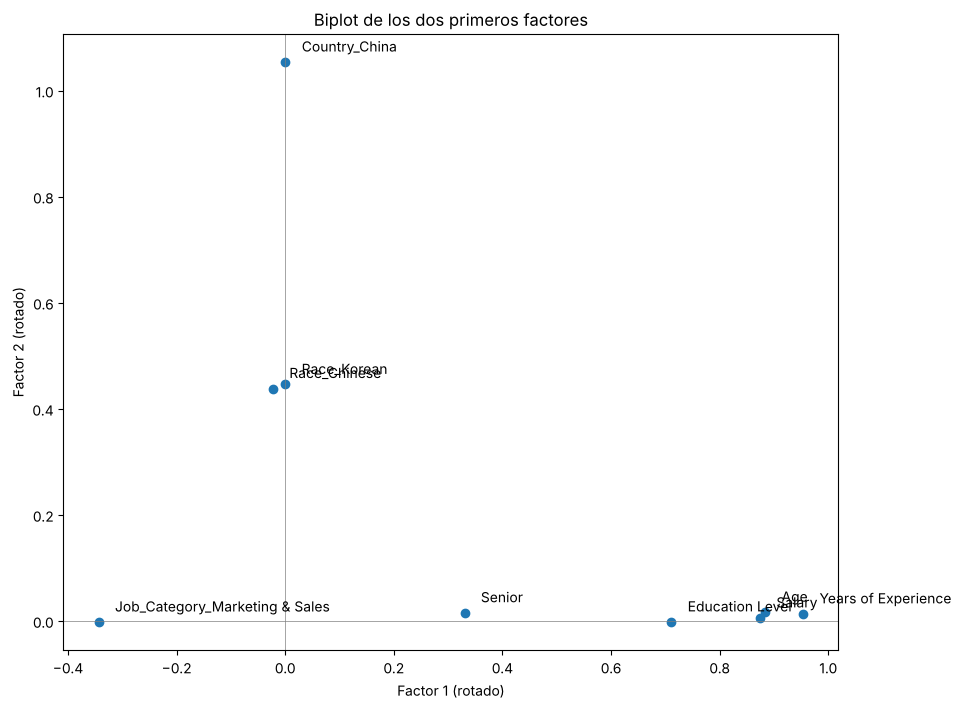

In [63]:
mask = (loadings2.abs() > 0.3).any(axis=1)
df_biplot = loadings2[mask]

#Crear biplot
plt.figure(figsize=(10, 8))
plt.scatter(df_biplot['Factor_1_rot'], df_biplot['Factor_2_rot'])

for var in df_biplot.index:
    x = df_biplot.loc[var, 'Factor_1_rot']
    y = df_biplot.loc[var, 'Factor_2_rot']
    plt.text(x + 0.03, y + 0.02, var)

plt.axhline(0, color='grey', linewidth=0.5)
plt.axvline(0, color='grey', linewidth=0.5)

plt.xlabel('Factor 1 (rotado)')
plt.ylabel('Factor 2 (rotado)')
plt.title('Biplot de los dos primeros factores')
plt.show()

### Comunalidades, unicidades y biplot

Los porcentajes de comunalidad indican cuánta varianza de cada variable es explicada por los dos factores seleccionadas tras rotación. Las comunalidades muestran una separación muy clara entre variables fuertemente representadas por los factores y variables prácticamente no explicadas por ellos.

Las variables **Age* (78%), **Education Level** (50%),**Years of Experience** (91%) y **Salary** (76%) presentan comunalidades muy altas. Esto significa que los dos factores capturan casi toda la estructura latente de estas variables. Estas variables están fuertemente asociadas al Factor 1, que representa la dimensión de trayectoria profesional.

Por el contrario, la mayoría de variables de país, raza y categorías laborales muestran comunalidades muy bajas (entre 0% y 12%), lo que indica que los factores seleccionados apenas explican su variabilidad. Estas variables no participan de manera significativa en la estructura factorial y su comportamiento depende de dimensiones que no han sido retenidas.

La unicidad es simplemente 1 - Comunalidad. Por eso, las variables con comunalidades altas tiene unicidades bajas, mientras que variables con comunalidades muy bajas tienen unicidades cercanas al 100%. Una unicidad alta significa que la variable no está representada por los factores y que su variabilidad proviene de dimensiones no incluidas en el modelo.

El biplot representa únicamente las variables con cargas mayores a 0.3 en alguno de los dos factores rotados. Esto hace que la visualización sea más clara y que solo aparezcan las variables realmente relevantes para la estructura latente.

Las variables **Age**, **Education Level**, **Years of Experience**, **Salary** y **Senior** se proyectan hacia el lado positvo del **Factor 1**. Su proximidad indica que estas variables comparten una estructura común y contribuyen de manera relevante a la explicación del modelo factorial.

Las variables de país, raza y varias categorías de trabajo aparecen dispersas, con vectores cortos y alejados del centro, lo que coincide con sus comunalidades bajas (excepto por *Country_China*). Esto indica que los factores retenidos no capturan bien su variabilidad y que su representación en el espacio factorial es limitada. Algunas categorías laborales, como Marketing & Sales, muestran cierta asociación con el Factor 2, pero en general estas variables no forman agrupaciones claras.

### Regresión logística con regularización LASSO

In [64]:
#Alinear variable objetivo con datos preparados
y_log = data_log.loc[data_log_num.index, 'Gender_bin'].values

#Train/Test split
X_log_train, X_log_test, y_log_train, y_log_test = train_test_split(
    X_fa_df, y_log, test_size=0.2, random_state=42, stratify=y_log
)

print(f"Train: {X_log_train.shape[0]} | Test: {X_log_test.shape[0]}")
print(f"Distribución objetivo train: {pd.Series(y_log_train).value_counts().to_dict()}")

Train: 5265 | Test: 1317
Distribución objetivo train: {1: 2923, 0: 2342}


In [65]:
#Regresión Logística con LASSO
X_log_train_const = sm.add_constant(X_log_train)

logit_lasso = sm.Logit(y_log_train, X_log_train_const)
result_lasso = logit_lasso.fit_regularized(
    method='l1',
    alpha=0.1,
    maxiter=200,
    disp=True
)

print(result_lasso.summary())

Iteration limit reached    (Exit mode 9)
            Current function value: 0.6418663612937294
            Iterations: 200
            Function evaluations: 201
            Gradient evaluations: 201


                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 5265
Model:                          Logit   Df Residuals:                     5235
Method:                           MLE   Df Model:                           29
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                 0.06587
Time:                        19:45:58   Log-Likelihood:                -3379.0
converged:                      False   LL-Null:                       -3617.3
Covariance Type:            nonrobust   LLR p-value:                 1.858e-82
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const                                 0.2227      0.030      7.512      0.000       0.165       0.281
Age                                   0.7237      0.093      7

### Resultados del modelo logístico en entrenamiento

En vista de las métricas y resultados obtenidos, el modelo logit muestra un desempeño limitado al predecir los valores del conjunto de train. La falta de convergencia, los errores estándar extremadamente elevados y la presencia de coeficientes no estimables indican que el modelo no logra capturar adecuadamente la relación entre las variables.

Esto es confirmado por el valor del Pseudo-R2, que es 0.065. Esto significa que el modelo solo mejora alrededor de un 6% respecto al modelo nulo. Un valor tan bajo indica que la estructura de la variable objetivo no está siendo explicada por las variables incluidas en el modelo.

En cuanto a los coeficientes estimados, la categoría *Race_Mixed* presenta un valor prácticamente igual a cero, acompañado por un error estándar enorme. Esto implica que el modelo no ha podido estimar un efecto real para esta categoría y que su presencia no modifica los odds.

Respecto a las categorías de *Receptionist* y *Front End Developer* de la variable **Job_Title**, estas o aparecen en el modelo porque fueron recodificadas dentro de categorías más amplias durante el preprocesamiento.

### Validación en el conjunto de test

In [66]:
# Clasificar los registros del conjunto de validación aplicando el modelo entrenado
X_log_test_const = sm.add_constant(X_log_test)

y_proba_test = result_lasso.predict(X_log_test_const)
y_pred_test  = (y_proba_test >= 0.5).astype(int)

In [67]:
# Calcular la matriz de confusión y sus métricas
cm = confusion_matrix(y_log_test, y_pred_test)
cm_pct = cm.astype(float) / cm.sum() * 100

print("Matriz de Confusión (valores absolutos):")
print(cm)
print()
print("Matriz de Confusión (porcentajes):")
print(np.round(cm_pct, 2))
print()
print("Reporte de Clasificación:")
print(classification_report(y_log_test, y_pred_test, target_names=['Female (0)', 'Male (1)']))

Matriz de Confusión (valores absolutos):
[[235 351]
 [144 587]]

Matriz de Confusión (porcentajes):
[[17.84 26.65]
 [10.93 44.57]]

Reporte de Clasificación:
              precision    recall  f1-score   support

  Female (0)       0.62      0.40      0.49       586
    Male (1)       0.63      0.80      0.70       731

    accuracy                           0.62      1317
   macro avg       0.62      0.60      0.60      1317
weighted avg       0.62      0.62      0.61      1317



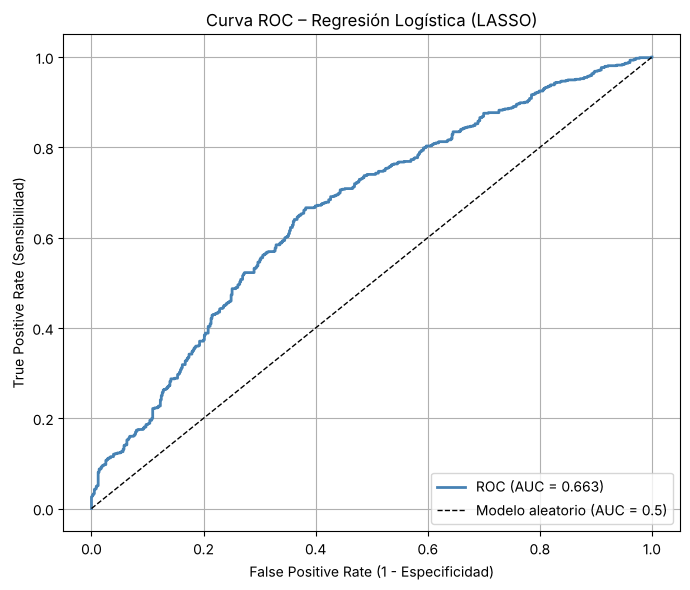


AUC-ROC: 0.6625


In [68]:
# Mostrar la curva ROC y calcular el area bajo la curva.
fpr, tpr, thresholds = roc_curve(y_log_test, y_proba_test)
auc_score = roc_auc_score(y_log_test, y_proba_test)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='steelblue', lw=2, label=f'ROC (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Modelo aleatorio (AUC = 0.5)')
plt.xlabel('False Positive Rate (1 - Especificidad)')
plt.ylabel('True Positive Rate (Sensibilidad)')
plt.title('Curva ROC – Regresión Logística (LASSO)')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"\nAUC-ROC: {auc_score:.4f}")

### Validación del modelo logístico

Los resultados obtenidos muestran que el modelo acierta un 62% de las predicciones, lo cual significa que funciona “más o menos”, pero no es bueno.

Al analizar el recall, se observa que la categoría *Female* (0) tiene un valor bajo (0.40), lo que significa que el modelo solo identifica correctamente el 40% de las mujeres presentes en el conjunto de datos. En contrates, la categoría *Male* (1) presenta un recall mucho más alto (0.80), indicando que el modelo detecta correctamente la mayoría de los hombres.

Esto quiere decir que el modelo está “inclinado” hacia la clase 1 y se equivoca mucho más cuando intenta identificar la clase 0.

El área bajo la curva ROC (AUC) es 0.663, lo que indica que el modelo distingue las dos clases mejor que el azar, pero aún insuficiente para considerarlo un buen clasificador.

En resumen, considerando todas las métricas, la matriz de confusión y el AUC, la conclusión es que el modelo no es muy fiable. Acierta algo más de la mitad de las veces, funciona mejor con una clase que con la otra y no tiene una capacidad fuerte para diferenciar correctamente entre hombres y mujeres.

## 11. Clustering jerárquico aglomerativo

Para el clustering uso `Salary.csv`, que contiene los mismos empleados sin nulos ni outliers, y trabajo sobre una copia para poder interpretar los grupos con los valores originales.

In [69]:
data_clust = pd.read_csv('datos/Salary.csv')
print("Shape del dataset original:", data_clust.shape)
data_clust.head()

Shape del dataset original: (6684, 9)


,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Country,Race,Senior
0,32.0,Male,1,Software Engineer,5.0,90000.0,UK,White,0
1,28.0,Female,2,Data Analyst,3.0,65000.0,USA,Hispanic,0
2,45.0,Male,3,Manager,15.0,150000.0,Canada,White,1
3,36.0,Female,1,Sales Associate,7.0,60000.0,USA,Hispanic,0
4,52.0,Male,2,Director,20.0,200000.0,USA,Asian,0


In [70]:
#Guardar una copia sin transformar para interpretar clusters
data_copy = data_clust.copy()

In [71]:
#Categorización
data['Age_group'] = pd.cut(data['Age'],
                         bins=[18, 30, 45, 60, 80],
                         labels=['Young', 'Adult', 'MidAge', 'Senior'])

data['YoE_group'] = pd.cut(data['Years of Experience'],
                         bins=[0, 5, 10, 20, 40],
                         labels=['Junior', 'Mid', 'Senior', 'Expert'])

In [72]:
#Recategorizar Job Title igual que antes
data_copy['Job_Category'] = data_copy['Job Title'].apply(categorize_job)
data_copy = data_copy.drop(columns=['Job Title'])

In [73]:
if 'Age_group' not in data_copy.columns:
    data_copy['Age_group'] = pd.cut(data_copy['Age'],
                                     bins=[18, 30, 45, 60, 80],
                                     labels=['Young', 'Adult', 'MidAge', 'Senior'])

if 'YoE_group' not in data_copy.columns:
    data_copy['YoE_group'] = pd.cut(data_copy['Years of Experience'],
                                     bins=[0, 5, 10, 20, 40],
                                     labels=['Junior', 'Mid', 'Senior', 'Expert'])

vars_cluster = [
    'Age', 'Salary', 'Years of Experience',
    'Gender', 'Race', 'Job_Category',
    'Age_group', 'YoE_group'
]

data_cluster = data_copy[vars_cluster].copy()

In [74]:
#Codificación
cat_vars = data_cluster.select_dtypes(include=['object', 'category']).columns
num_vars = data_cluster.select_dtypes(include=['int64', 'float64']).columns

encoder = OneHotEncoder(drop='first', sparse_output=False)
encoded = encoder.fit_transform(data_cluster[cat_vars])

encoded_df = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(cat_vars))

In [75]:
#Normalización
scaler = StandardScaler()
scaled_num = scaler.fit_transform(data_cluster[num_vars])
scaled_num_df = pd.DataFrame(scaled_num, columns=num_vars)

In [76]:
#Dataset final
X_cluster = pd.concat([scaled_num_df, encoded_df], axis=1)
print("Shape datos para clustering (estandarizados):", X_cluster.shape)

Shape datos para clustering (estandarizados): (6684, 28)


### Matriz de distancias y dendrogramas (enlaces Ward y Complete)

In [77]:
#Matriz de distancias (vector condensado)
dist_matrix = pdist(X_cluster, metric='euclidean')

#Convertir a matriz cuadrada
dist_square = squareform(dist_matrix)

print(dist_square)


[[0.         2.57129457 3.31237986 ... 2.55660101 3.67731003 2.85467544]
 [2.57129457 0.         4.42296572 ... 2.03290782 4.46795976 2.1218344 ]
 [3.31237986 4.42296572 0.         ... 4.05783941 1.75519588 4.93895606]
 ...
 [2.55660101 2.03290782 4.05783941 ... 0.         4.09634674 2.16065256]
 [3.67731003 4.46795976 1.75519588 ... 4.09634674 0.         4.95352541]
 [2.85467544 2.1218344  4.93895606 ... 2.16065256 4.95352541 0.        ]]


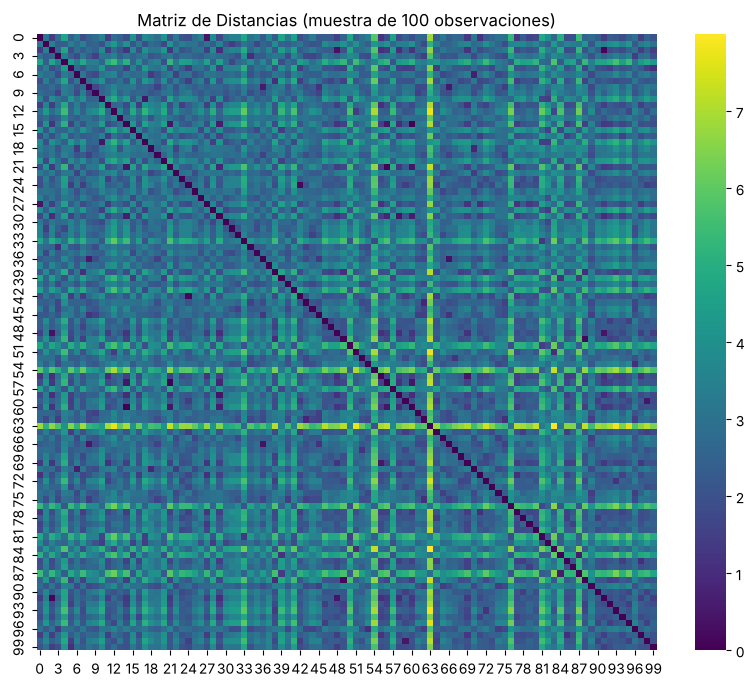

Dimensiones matriz de distancias: (6684, 6684)


In [78]:
#Visualización con una muestra
np.random.seed(42)
sample_idx = np.random.choice(len(X_cluster), size=100, replace=False)
dist_sample = squareform(pdist(X_cluster.iloc[sample_idx], metric='euclidean'))

plt.figure(figsize=(10, 8))
sns.heatmap(dist_sample, cmap='viridis')
plt.title("Matriz de Distancias (muestra de 100 observaciones)")
plt.show()

print("Dimensiones matriz de distancias:", dist_square.shape)

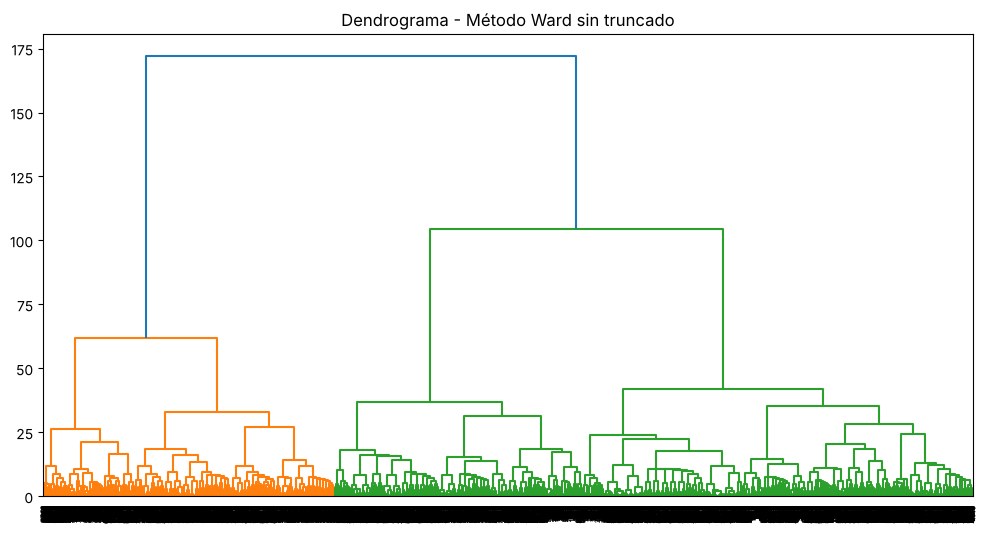

In [79]:
#Clustering enlace WARD sin truncate
Z_ward = linkage(X_cluster, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(Z_ward)
plt.title("Dendrograma - Método Ward sin truncado")
plt.show()

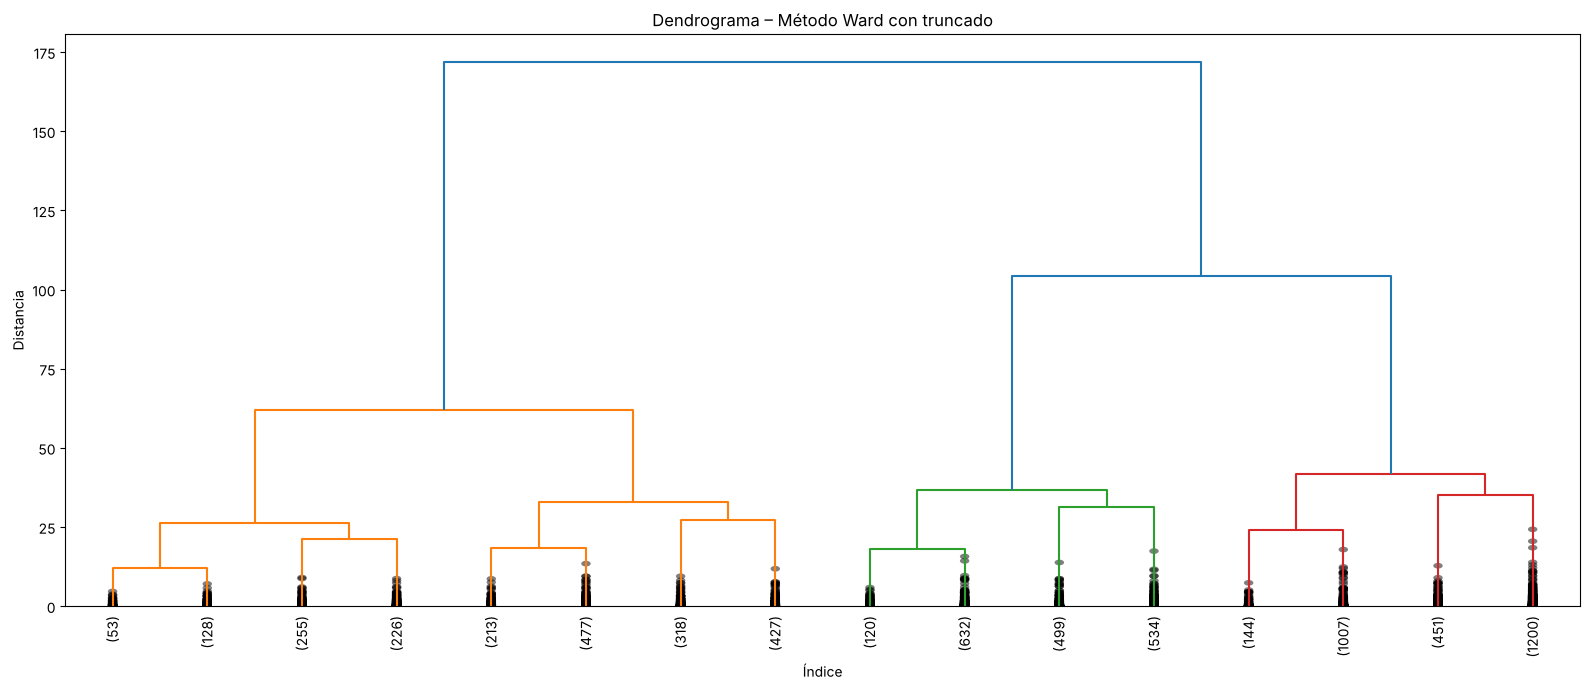

In [80]:
#Clustering enlace WARD con truncate
Z_ward = linkage(X_cluster, method='ward', metric='euclidean')

plt.figure(figsize=(16, 7))
dendrogram(Z_ward, truncate_mode='level', p=3,
           leaf_rotation=90, leaf_font_size=10,
           show_contracted=True, color_threshold=0.5*max(Z_ward[:,2]))
plt.title('Dendrograma – Método Ward con truncado')
plt.xlabel('Índice')
plt.ylabel('Distancia')
plt.tight_layout()
plt.show()

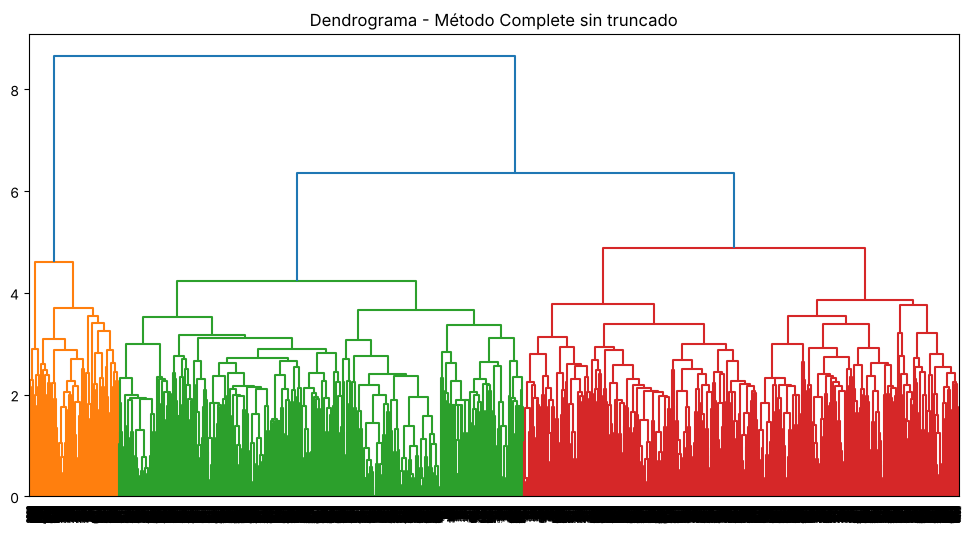

In [81]:
#Clustering enlace COMPLETE sin truncate
Z_complete = linkage(X_cluster, method="complete")

plt.figure(figsize=(12, 6))
dendrogram(Z_complete)
plt.title("Dendrograma - Método Complete sin truncado")
plt.show()

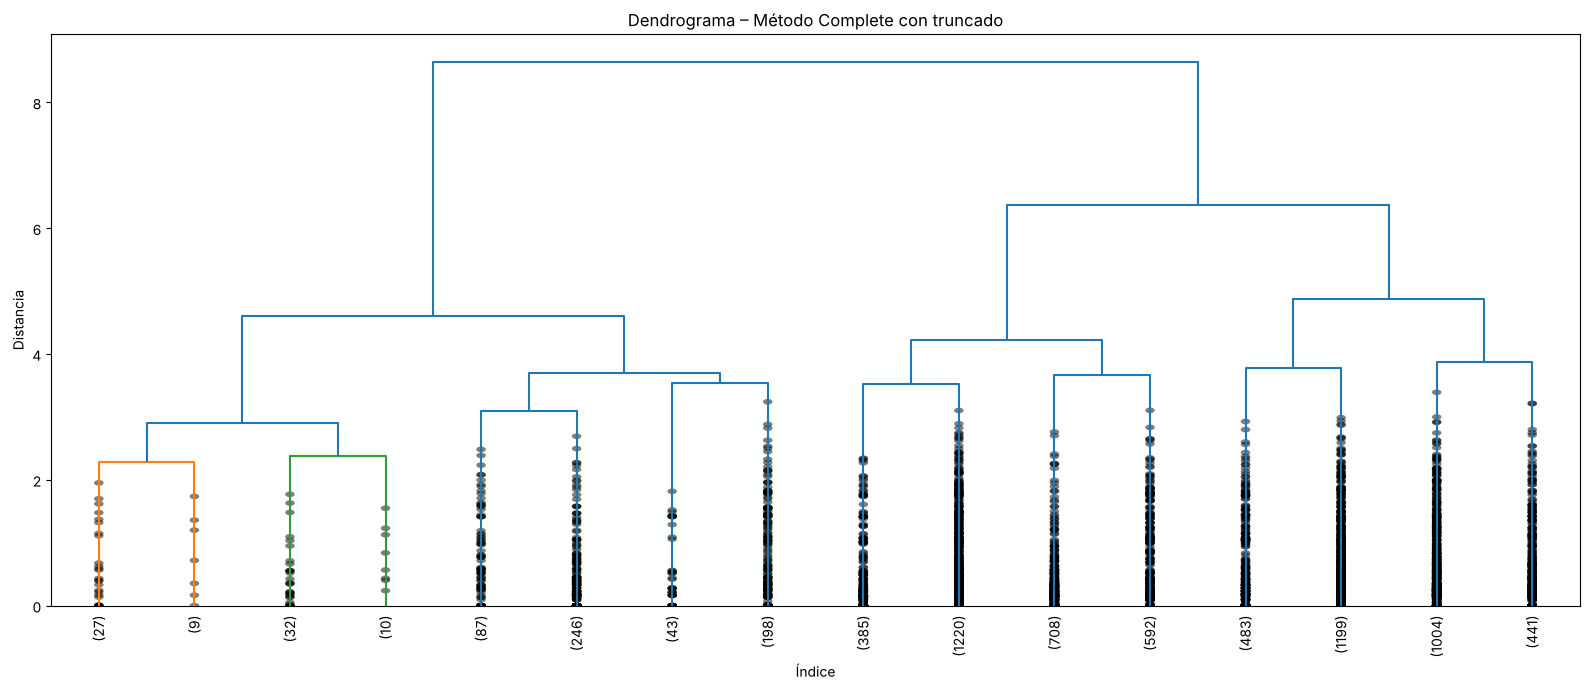

In [82]:
#Clustering enlace COMPLETE con truncate mode
Z_complete = linkage(X_cluster, method='complete', metric='euclidean')

plt.figure(figsize=(16, 7))
dendrogram(Z_complete, truncate_mode='level', p=3,
           leaf_rotation=90, leaf_font_size=10,
           show_contracted=True, color_threshold=0.3*max(Z_complete[:,2]))
plt.title('Dendrograma – Método Complete con truncado')
plt.xlabel('Índice')
plt.ylabel('Distancia')
plt.tight_layout()
plt.show()

### Número de clusters

A la vista de los dendrogramas obtenidos para cada función de enlace, se ha decidido agrupar los datos en 3 clusters tanto para el método Ward como para el método Complete.

En ambos casos, los dendrogramas sin truncado muestran un salto claro en las fusiones finales, mientras que los dendrogramas con truncado permiten visualizar de forma más nítida tres grupos principales de observaciones.

Una partición en 3 clusters es la opción más adecuada para ambos métodos de enlace.

### Asignación y caracterización de los clusters

In [83]:
#Asignar etiquetas de cluster
n_clusters_ward     = 3
n_clusters_complete = 3

#Asignar clusters a la muestra
labels_ward     = fcluster(Z_ward,     t=n_clusters_ward,     criterion='maxclust')
labels_complete = fcluster(Z_complete, t=n_clusters_complete, criterion='maxclust')

#Agregar al índice de la muestra
sample_data_original = data_copy.iloc[sample_idx].copy()
sample_data_original['Cluster_Ward']     = labels_ward[sample_idx]
sample_data_original['Cluster_Complete'] = labels_complete[sample_idx]

print("Tamaño de cada cluster (Ward):")
print(sample_data_original['Cluster_Ward'].value_counts().sort_index())
print()
print("Tamaño de cada cluster (Complete):")
print(sample_data_original['Cluster_Complete'].value_counts().sort_index())

Tamaño de cada cluster (Ward):
Cluster_Ward
1    24
2    27
3    49
Name: count, dtype: int64

Tamaño de cada cluster (Complete):
Cluster_Complete
1     8
2    50
3    42
Name: count, dtype: int64


In [84]:
#Métricas para interpretar los clusters
print("Análisis de Clusters – Enlace WARD")

for col in ['Age', 'Years of Experience', 'Salary', 'Education Level', 'Senior']:
    print(f"\n── {col} ──")
    print(sample_data_original.groupby('Cluster_Ward')[col].agg(['mean','median','count']).round(1))

print("\n── Gender ──")
print(sample_data_original.groupby(['Cluster_Ward', 'Gender']).size().unstack(fill_value=0))

print("\n── Job Category ──")
print(sample_data_original.groupby(['Cluster_Ward', 'Job_Category']).size().unstack(fill_value=0))

Análisis de Clusters – Enlace WARD

── Age ──
              mean  median  count
Cluster_Ward                     
1             43.5    43.0     24
2             32.9    33.0     27
3             27.8    29.0     49

── Years of Experience ──
              mean  median  count
Cluster_Ward                     
1             15.8    15.0     24
2              7.9     8.0     27
3              2.9     3.0     49

── Salary ──
                  mean    median  count
Cluster_Ward                           
1             169838.8  170000.0     24
2             122878.3  121120.0     27
3              59773.0   55000.0     49

── Education Level ──
              mean  median  count
Cluster_Ward                     
1              2.4     3.0     24
2              1.9     2.0     27
3              0.9     1.0     49

── Senior ──
              mean  median  count
Cluster_Ward                     
1              0.5     0.0     24
2              0.1     0.0     27
3              0.0     0.0    

In [85]:
print("Análisis de Clusters – Enlace COMPLETE")

for col in ['Age', 'Years of Experience', 'Salary', 'Education Level', 'Senior']:
    print(f"\n── {col} ──")
    print(sample_data_original.groupby('Cluster_Complete')[col].agg(['mean','median','count']).round(1))

print("\n── Country ──")
print(sample_data_original.groupby(['Cluster_Complete', 'Country']).size().unstack(fill_value=0))

Análisis de Clusters – Enlace COMPLETE

── Age ──
                  mean  median  count
Cluster_Complete                     
1                 49.8    49.0      8
2                 27.8    28.5     50
3                 35.9    34.0     42

── Years of Experience ──
                  mean  median  count
Cluster_Complete                     
1                 20.8    19.0      8
2                  2.9     3.0     50
3                 10.0     9.0     42

── Salary ──
                      mean    median  count
Cluster_Complete                           
1                 187633.5  187500.0      8
2                  60677.5   55000.0     50
3                 137804.2  130000.0     42

── Education Level ──
                  mean  median  count
Cluster_Complete                     
1                  2.8     3.0      8
2                  0.9     1.0     50
3                  2.0     2.0     42

── Senior ──
                  mean  median  count
Cluster_Complete                     
1     

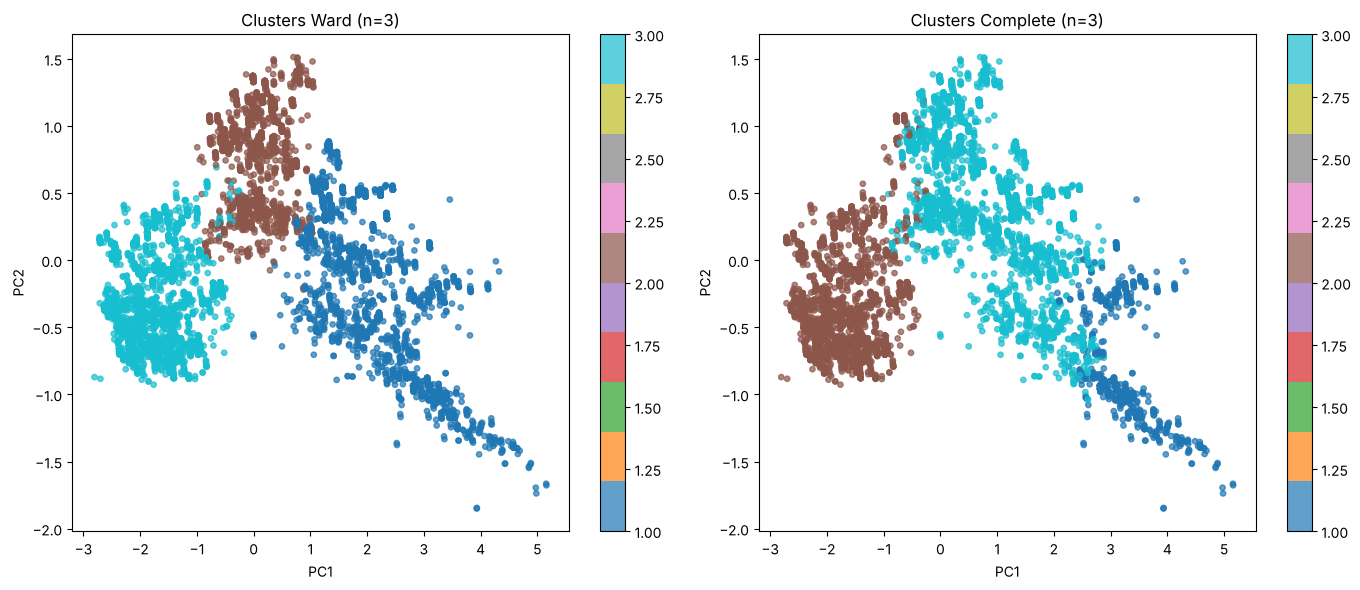

In [86]:
pca_vis = PCA(n_components=2)
X_2d = pca_vis.fit_transform(X_cluster)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sc1 = axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=labels_ward, cmap='tab10', alpha=0.7, s=15)
axes[0].set_title(f'Clusters Ward (n={n_clusters_ward})')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
plt.colorbar(sc1, ax=axes[0])

sc2 = axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=labels_complete, cmap='tab10', alpha=0.7, s=15)
axes[1].set_title(f'Clusters Complete (n={n_clusters_complete})')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
plt.colorbar(sc2, ax=axes[1])

plt.tight_layout()
plt.show()

### Interpretación de los clusters

El método Ward identifica tres clusters, pero incorpora información adicional sobre género y categoría profesional. El Cluster 1 concentra a los profesionales con mayor experiencia (16 años de media) y los salarios más altos del conjunto, con predominio de categorías como Management y Tech Engineering, lo que sugiere que este grupo corresponde a mandos altos y líderes técnicos. El Cluster 2 representa perfiles de experiencia intermedia, con salarios igualmente elevados pero inferiores a los del grupo senior. Este cluster parece corresponder a mandos intermedios o especialistas técnicos. Por último, el Cluster 3 agrupa a los perfiles más jóvenes y con menor experiencia, caracterizados por salarios bajos y menor nivel educativo. Este grupo incluye empleados distribuidos en diversas áreas y representa claramente a los perfiles junior o early‑career dentro de la organización.


El método Complete también genera tres clusters que se organizan principalmente según la edad, la experiencia y el salario. El Cluster 1 reúne a los perfiles de mayor edad y trayectoria, con una media de 50 años y casi 21 años de experiencia, lo que se refleja en salarios muy elevados y en un nivel educativo superior. Este grupo representa claramente a profesionales senior y con roles de alta responsabilidad. El Cluster 2, por el contrario, agrupa a los perfiles más jóvenes del conjunto, con una media de 28 años, 3 años de experiencia y el salario más bajo. Se trata de empleados early-career o juniors, con menor formación. Finalmente, el Cluster 3 se sitúa en una posición intermedia. Los perfiles tienen alrededor de 36 años, unos 10 años de experiencia y salarios altos pero no tan elevados como los del grupo senior. Este cluster representa a profesionales mid‑career, con experiencia consolidada y buena remuneración, probablemente ocupando posiciones técnicas avanzadas o de responsabilidad media.

Ambos métodos coinciden en identificar tres grandes segmentos: un grupo senior con alta experiencia y salarios elevados, un grupo mid‑career con experiencia consolidada y buena remuneración, y un grupo junior con poca experiencia y salarios bajos. El método Complete enfatiza más las diferencias en edad y experiencia, mientras que Ward permite ver cómo estas diferencias se relacionan con las categorías profesionales y la estructura organizativa.